# ✈️ Prédiction de la satisfaction client & du prix des billets

**Jeu de données :** *Airline Passenger Satisfaction* — 129 880 clients, 25 variables décrivant
le profil du voyageur, le vol, ses notes de service (14 dimensions notées de 0 à 5), les retards
et le prix payé.

## Objectifs

| # | Objectif | Livrable |
|---|----------|----------|
| 1 | Auditer et nettoyer les données | jeu de données fiable, sans doublon ni valeur manquante |
| 2 | Comprendre les ressorts de la satisfaction | visualisations commentées |
| 3 | **Feature engineering** | indices de service, variables de retard, segments, interaction classe × distance |
| 4 | Prédire le **prix** du billet | baseline + 5 modèles, validation croisée, réglage, analyse des résidus |
| 5 | Prédire la **satisfaction** (classification binaire) | 4 modèles, matrice de confusion, courbes ROC, variables motrices |
| 6 | Passer de l'analyse à l'action | recommandations métier, limites, modèle sauvegardé et réutilisable |

## Sommaire

1. Configuration
2. Chargement et dictionnaire des données
3. Audit de la qualité des données
4. Nettoyage et traitement des valeurs manquantes
5. Analyse exploratoire (univariée → bivariée → multivariée)
6. Feature engineering
7. Tests statistiques
8. Préparation à la modélisation
9. Régression du prix
10. Optimisation du meilleur modèle de régression
11. Classification de la satisfaction
12. Synthèse, recommandations et limites
13. Sauvegarde du modèle et prédiction sur un nouveau client

## 1. Configuration

On fixe la graine aléatoire (reproductibilité), le style des figures et deux fonctions utilitaires :
`save()` pour exporter chaque figure dans `figures/`, et `note()` pour afficher une interprétation
mise en forme.

In [1]:
%matplotlib inline

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
import joblib

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5.4),
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PAL_SAT = {"dissatisfied": "#C0392B", "neutral": "#E1A100", "satisfied": "#1E8449"}
PAL_CLASS = {"Eco": "#4C72B0", "Eco Plus": "#DD8452", "Business": "#55A868"}
SAT_ORDER = ["dissatisfied", "neutral", "satisfied"]

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 150)


def save(fig, name):
    "Exporte la figure dans figures/ pour réutilisation dans un rapport."
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    return fig


def note(text):
    "Affiche une interprétation mise en forme (paragraphe unique)."
    corps = " ".join(str(text).split())
    display(Markdown(f"> **Interprétation.** {corps}"))


print("Environnement prêt · numpy", np.__version__, "· pandas", pd.__version__)

Environnement prêt · numpy 1.26.4 · pandas 2.1.4


## 2. Chargement et dictionnaire des données

Le fichier contient une colonne d'index exportée par erreur (``Unnamed: 0``) et un identifiant
technique (``id``) : ni l'une ni l'autre ne porte d'information métier, elles sont écartées.

In [2]:
DATA_PATH = "dataset.csv"

raw = pd.read_csv(DATA_PATH)
df = raw.drop(columns=["Unnamed: 0"], errors="ignore").copy()

print(f"{df.shape[0]:,} lignes × {df.shape[1]} colonnes".replace(",", " "))
print(f"Identifiant unique par client : {df['id'].is_unique}")
display(df.head())

129 880 lignes × 25 colonnes
Identifiant unique par client : True


,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,Price
0,19149,Female,disloyal Customer,19.0,Business travel,Eco,353.0,3,4,3.0,4.0,2,3,2,2,5,5.0,5,2,2,2,0,3.0,dissatisfied,565
1,69112,Male,Loyal Customer,54.0,Business travel,Eco Plus,1088.0,5,2,2.0,2.0,5,5,5,5,2,3.0,5,1,2,5,0,0.0,satisfied,2573
2,4725,Female,disloyal Customer,23.0,Business travel,Business,977.0,2,0,2.0,5.0,5,2,1,5,5,4.0,4,5,5,5,0,0.0,dissatisfied,2339
3,115546,Male,Loyal Customer,58.0,Business travel,Business,2932.0,2,3,3.0,3.0,5,3,4,2,2,2.0,2,1,2,1,15,11.0,dissatisfied,2695
4,59440,Male,Loyal Customer,45.0,Business travel,Eco,667.0,1,0,0.0,2.0,2,1,2,2,4,2.0,2,4,2,2,0,5.0,dissatisfied,622


In [3]:
synthese = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs_uniques": df.nunique(),
    "exemple": [df[c].dropna().iloc[0] for c in df.columns],
})
display(synthese)

,type,valeurs_uniques,exemple
id,int64,129880,19149
Gender,object,2,Female
Customer Type,object,2,disloyal Customer
Age,float64,68,19.0
Type of Travel,object,2,Business travel
Class,object,3,Eco
Flight Distance,float64,3821,353.0
Inflight wifi service,int64,6,3
Departure/Arrival time convenient,int64,6,4
Ease of Online booking,float64,6,3.0


### Dictionnaire des variables

| Variable | Type | Description |
|---|---|---|
| `Gender` | catégorielle | sexe du passager |
| `Customer Type` | catégorielle | client fidèle (*Loyal*) ou non |
| `Age` | numérique | âge (6–76 ans) |
| `Type of Travel` | catégorielle | voyage d'affaires ou personnel |
| `Class` | catégorielle | cabine : Eco, Eco Plus, Business |
| `Flight Distance` | numérique | distance du vol (miles) |
| 14 variables de service | ordinales 0–5 | wifi, confort du siège, embarquement en ligne, propreté, personnel, bagages… |
| `Departure Delay in Minutes` | numérique | retard au départ |
| `Arrival Delay in Minutes` | numérique | retard à l'arrivée (avec valeurs manquantes) |
| `satisfaction` | catégorielle | **cible 1** : *dissatisfied*, *neutral*, *satisfied* |
| `Price` | numérique | **cible 2** : prix du billet (141–4 726) |

Deux cibles ⇒ deux problèmes d'apprentissage : une **régression** (prix) et une **classification**
(satisfaction). La satisfaction à trois modalités sera ramenée à un problème binaire
(*satisfied* vs *non satisfied*) dans la section 11.

## 3. Audit de la qualité des données

Avant de nettoyer, on mesure : valeurs manquantes, doublons, colonnes constantes, ordres de grandeur
et valeurs extrêmes. Chaque constat débouche sur une décision explicite (section 4).

In [4]:
audit = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "manquant": df.isna().sum(),
    "manquant_%": (df.isna().mean() * 100).round(2),
})
audit = audit[audit["manquant"] > 0].sort_values("manquant", ascending=False)
display(audit)

print("Doublons stricts                :", df.duplicated().sum())
print("Doublons hors identifiant       :", df.drop(columns=["id"]).duplicated().sum())
print("Colonnes constantes             :", [c for c in df.columns if df[c].nunique() <= 1])
print("Total de cellules manquantes    :", int(df.isna().sum().sum()))
print(f"→ soit {df.isna().any(axis=1).mean():.2%} des lignes concernées par au moins une valeur manquante")

,type,manquant,manquant_%
Arrival Delay in Minutes,float64,393,0.3
Leg room service,float64,133,0.1
Ease of Online booking,float64,131,0.1
Gate location,float64,130,0.1
Age,float64,126,0.1


Doublons stricts                : 0
Doublons hors identifiant       : 0
Colonnes constantes             : []
Total de cellules manquantes    : 913
→ soit 0.70% des lignes concernées par au moins une valeur manquante


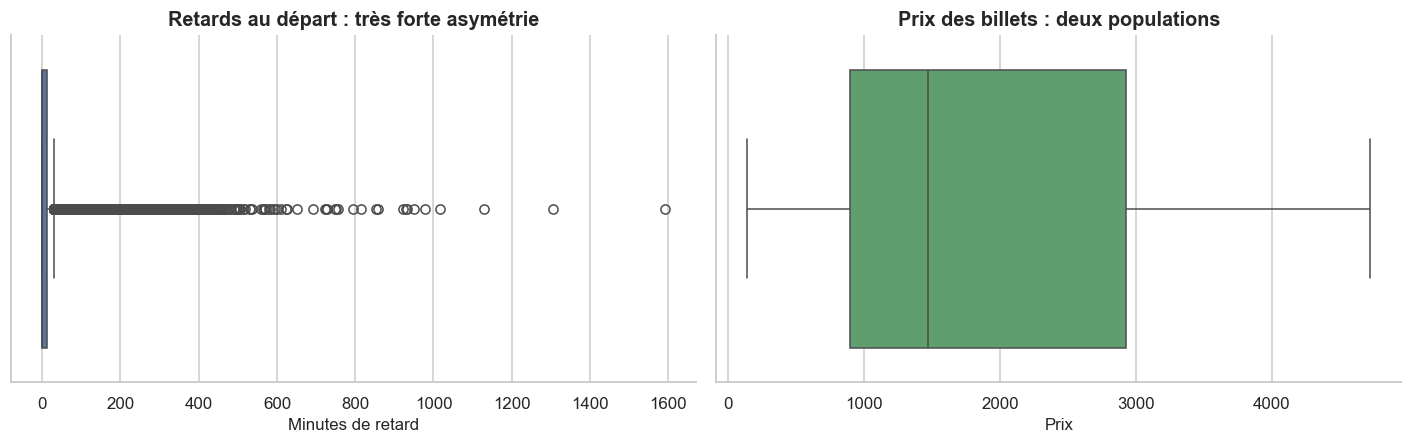

Vols en retard de plus de 3 h : 1290
Retard maximal observé        : 1592 min
          count    mean     std    min    25%     50%     75%     max
Price  129880.0  1883.0  1164.0  141.0  895.0  1472.0  2925.0  4726.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.boxplot(x=df["Departure Delay in Minutes"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Retards au départ : très forte asymétrie")
axes[0].set_xlabel("Minutes de retard")

sns.boxplot(x=df["Price"], ax=axes[1], color="#55A868")
axes[1].set_title("Prix des billets : deux populations")
axes[1].set_xlabel("Prix")

fig.tight_layout()
save(fig, "01_audit_extremes")
plt.show()

print("Vols en retard de plus de 3 h :", int((df["Departure Delay in Minutes"] > 180).sum()))
print("Retard maximal observé        :", int(df["Departure Delay in Minutes"].max()), "min")
print(df["Price"].describe().round(0).to_frame().T)

**Constats de l'audit**

* **Aucun doublon** : 129 880 clients, 129 880 identifiants uniques. Aucune déduplication nécessaire.
* **5 colonnes incomplètes**, pour seulement 0,1 % à 0,3 % des lignes (≈ 400 lignes au total) :
  `Age`, `Ease of Online booking`, `Gate location`, `Leg room service`, `Arrival Delay in Minutes`.
  Le taux est trop faible pour jeter des lignes : on impute.
* **Retards très asymétriques** : médiane à 0 min, maximum à 1 592 min (26 h). Moins de 1 % des vols
  dépassent 3 h, mais ces valeurs extrêmes pèsent lourd dans une moyenne ou dans un modèle linéaire.
* **Prix bimodal**, avec deux populations nettement séparées : les billets Eco (~880) et les billets
  Business (~2 980). C'est le reflet direct des cabines, pas une anomalie.

**Décisions** : imputation par la médiane (variable peu dispersée, robuste aux extrêmes) ; pour le
retard à l'arrivée, une **règle métier** plutôt qu'une médiane globale ; winsorisation des retards
au 99,5ᵉ centile ; conservation des prix extrêmes, qui sont des billets Business légitimes.

## 4. Nettoyage et traitement des valeurs manquantes

Trois choix structurent cette étape :

1. **Renommage en `snake_case`** : `Seat comfort` → `seat_comfort`. Indispensable pour écrire du code
   lisible et sans ambiguïté (`baggage`, `checkin`…).
2. **Imputation par la médiane** pour l'âge et les notes de service : la médiane ne dépend pas des
   valeurs extrêmes et conserve l'échelle ordinale 0–5 des notes.
3. **Règle métier pour le retard à l'arrivée** : un vol qui part en retard arrive en retard. On impute
   donc `arrival_delay = departure_delay + décalage médian`, plutôt qu'une valeur arbitraire. Un
   indicateur `arrival_delay_missing` conserve l'information « donnée absente », qui peut être
   informative et sera proposée au modèle.

In [6]:
RENAMES = {
    "Gender": "gender",
    "Customer Type": "customer_type",
    "Age": "age",
    "Type of Travel": "travel_type",
    "Class": "cabin_class",
    "Flight Distance": "flight_distance",
    "Inflight wifi service": "wifi",
    "Departure/Arrival time convenient": "time_convenient",
    "Ease of Online booking": "online_booking",
    "Gate location": "gate_location",
    "Food and drink": "food_drink",
    "Online boarding": "online_boarding",
    "Seat comfort": "seat_comfort",
    "Inflight entertainment": "entertainment",
    "On-board service": "onboard_service",
    "Leg room service": "leg_room",
    "Baggage handling": "baggage",
    "Checkin service": "checkin",
    "Inflight service": "inflight_service",
    "Cleanliness": "cleanliness",
    "Departure Delay in Minutes": "departure_delay",
    "Arrival Delay in Minutes": "arrival_delay",
    "satisfaction": "satisfaction",
    "Price": "price",
}
df = df.rename(columns=RENAMES)

SERVICES = [
    "wifi", "time_convenient", "online_booking", "gate_location", "food_drink",
    "online_boarding", "seat_comfort", "entertainment", "onboard_service",
    "leg_room", "baggage", "checkin", "inflight_service", "cleanliness",
]
SERVICE_LABELS = {
    "wifi": "Wifi à bord",
    "time_convenient": "Horaires pratiques",
    "online_booking": "Réservation en ligne",
    "gate_location": "Localisation de la porte",
    "food_drink": "Restauration",
    "online_boarding": "Embarquement en ligne",
    "seat_comfort": "Confort du siège",
    "entertainment": "Divertissement à bord",
    "onboard_service": "Service à bord",
    "leg_room": "Espace jambes",
    "baggage": "Bagages",
    "checkin": "Enregistrement",
    "inflight_service": "Service en vol",
    "cleanliness": "Propreté",
}

manquants_avant = int(df.isna().sum().sum())

# (1) mémoire du caractère manquant, avant imputation
df["arrival_delay_missing"] = df["arrival_delay"].isna().astype(int)

# (2) âge : médiane
df["age"] = df["age"].fillna(df["age"].median())

# (3) notes de service : médiane (échelle ordinale 0-5)
for col in ["online_booking", "gate_location", "leg_room"]:
    df[col] = df[col].fillna(df[col].median())

# (4) retard à l'arrivée : règle métier (retard départ + décalage médian)
offset = (df["arrival_delay"] - df["departure_delay"]).median()
df["arrival_delay"] = df["arrival_delay"].fillna(df["departure_delay"] + offset)

# (5) winsorisation des retards au 99,5e centile
CAP_DELAY = df["departure_delay"].quantile(0.995)
df["departure_delay"] = df["departure_delay"].clip(upper=CAP_DELAY)
df["arrival_delay"] = df["arrival_delay"].clip(upper=CAP_DELAY)

# (6) variables d'analyse dérivées (recalculées à l'identique en section 6)
df["total_delay"] = df["departure_delay"] + df["arrival_delay"]
df["satisfied"] = (df["satisfaction"] == "satisfied").astype(int)
df["prix_par_mile"] = df["price"] / df["flight_distance"]

# (7) identifiant technique : aucune information prédictive
df = df.drop(columns=["id"])

print(f"Cellules manquantes avant : {manquants_avant}")
print(f"Cellules manquantes après : {int(df.isna().sum().sum())}")
print(f"Retard plafonné à         : {CAP_DELAY:.0f} min")
print(f"Dimensions finales        : {df.shape}")

Cellules manquantes avant : 913
Cellules manquantes après : 0
Retard plafonné à         : 232 min
Dimensions finales        : (129880, 28)


## 5. Analyse exploratoire

### 5.1 La cible : trois niveaux de satisfaction

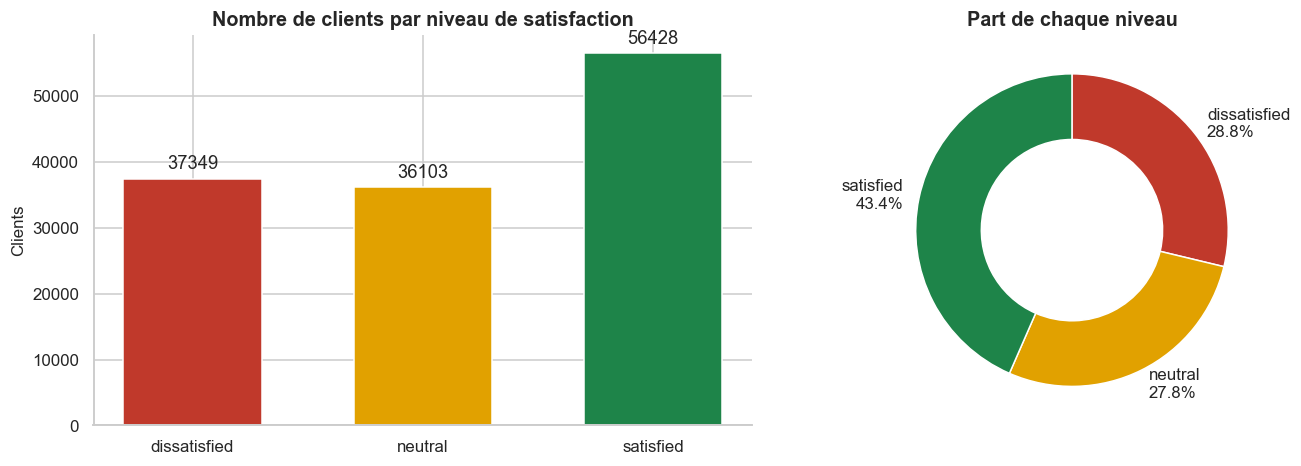

Taux de satisfaction (satisfied) : 43.4%


In [7]:
counts = df["satisfaction"].value_counts().reindex(SAT_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

bars = axes[0].bar(counts.index, counts.values, color=[PAL_SAT[k] for k in counts.index], width=0.6)
axes[0].bar_label(bars, fmt="%d", padding=4)
axes[0].set_title("Nombre de clients par niveau de satisfaction")
axes[0].set_ylabel("Clients")
axes[0].set_xlabel("")

axes[1].pie(
    counts,
    labels=[f"{k}\n{v / counts.sum():.1%}" for k, v in counts.items()],
    colors=[PAL_SAT[k] for k in counts.index],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor="white"),
)
axes[1].set_title("Part de chaque niveau")

fig.tight_layout()
save(fig, "02_cible_satisfaction")
plt.show()

print(f"Taux de satisfaction (satisfied) : {df['satisfied'].mean():.1%}")

**Interprétation.** Les trois classes sont déséquilibrées mais aucune n'est marginale :
43,5 % de clients satisfaits, 28,8 % insatisfaits, 27,8 % neutres. Deux conséquences :

* l'**accuracy seule sera trompeuse** (un modèle qui prédit toujours « satisfait » atteint déjà 43 %) ;
  il faudra regarder précision, rappel, F1 et AUC ;
* la classe *neutral* est ambiguë métier (ni promoteur ni détracteur). Pour la classification, on la
  regroupe avec *dissatisfied* : la question devient **« ce client est-il satisfait, oui ou non ? »**,
  ce qui correspond à l'usage opérationnel (cibler les clients à risque). L'analyse à trois classes
  reste pertinente en descriptive, et c'est elle qu'on utilise dans toute l'EDA.

### 5.2 Le prix des billets

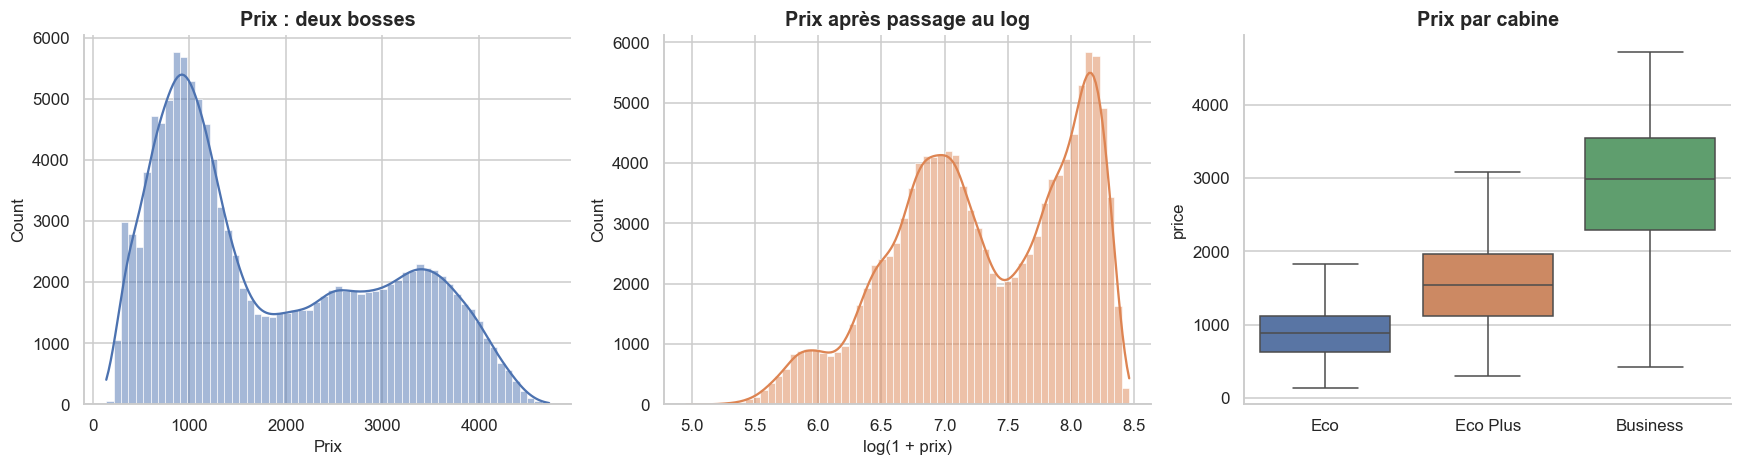

,count,mean,std,min,25%,50%,75%,max
cabin_class,,,,,,,,
Eco,58309.0,878.0,325.0,141.0,632.0,879.0,1122.0,1827.0
Eco Plus,9411.0,1542.0,568.0,301.0,1111.0,1538.0,1968.0,3087.0
Business,62160.0,2877.0,855.0,424.0,2296.0,2982.0,3544.0,4726.0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

sns.histplot(df["price"], bins=60, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Prix : deux bosses")
axes[0].set_xlabel("Prix")

sns.histplot(np.log1p(df["price"]), bins=60, kde=True, ax=axes[1], color="#DD8452")
axes[1].set_title("Prix après passage au log")
axes[1].set_xlabel("log(1 + prix)")

sns.boxplot(
    data=df, x="cabin_class", y="price", order=["Eco", "Eco Plus", "Business"],
    hue="cabin_class", palette=PAL_CLASS, legend=False, ax=axes[2],
)
axes[2].set_title("Prix par cabine")
axes[2].set_xlabel("")

fig.tight_layout()
save(fig, "03_prix")
plt.show()

display(
    df.groupby("cabin_class")["price"]
      .describe()
      .reindex(["Eco", "Eco Plus", "Business"])
      .round(0)
)

**Interprétation.** Le prix n'est pas une loi continue : c'est un **mélange de trois populations**,
une par cabine.

| Cabine | Prix médian | Écart-type | Coefficient de variation |
|---|---|---|---|
| Eco | 879 | 325 | 37 % |
| Eco Plus | 1 538 | 568 | 37 % |
| Business | 2 982 | 855 | 30 % |

* La bimodalité du prix global est **entièrement expliquée par la cabine** : la classe est donc le
  premier facteur de prix, et un modèle qui l'ignore sera structurellement mauvais.
* La distribution reste asymétrique à droite (quelques billets très chers) : la transformation
  logarithmique la normalise, ce qui sera utile pour les modèles linéaires.
* Business est à la fois la cabine la plus chère **et** la plus homogène (CV 30 %), signe d'une
  grille tarifaire plus rigide.

### 5.3 Âge et distance : qui voyage, et jusqu'où ?

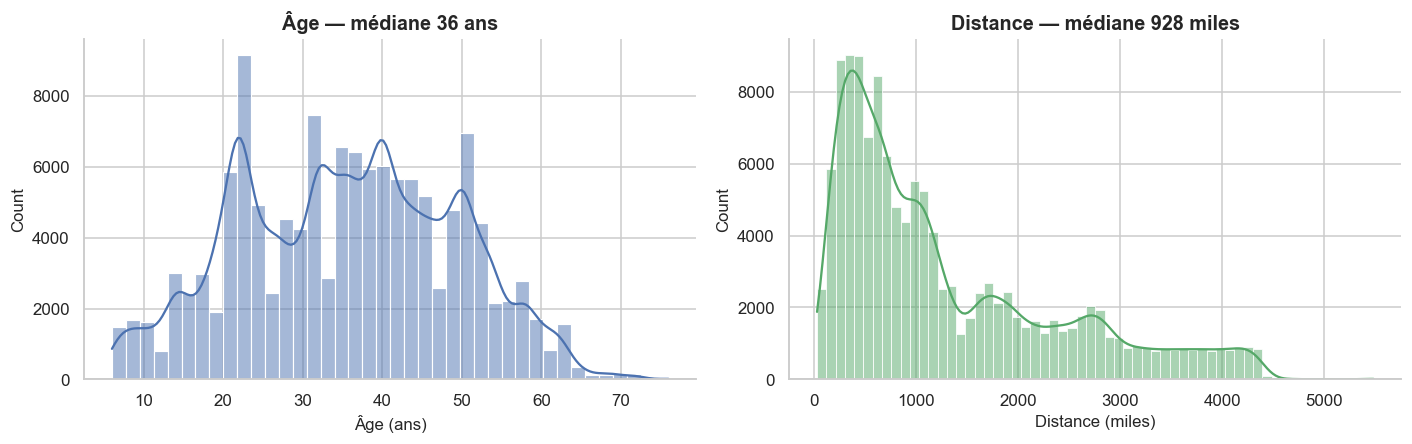

            age  flight_distance
count  129880.0         129880.0
mean       35.5           1309.4
std        13.6           1097.2
min         6.0             34.0
25%        24.0            455.0
50%        36.0            928.0
75%        46.0           1918.0
max        76.0           5481.0

Asymétrie (skewness) : {'age': -0.01, 'flight_distance': 1.11}


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(df["age"], bins=40, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Âge — médiane {df['age'].median():.0f} ans")
axes[0].set_xlabel("Âge (ans)")

sns.histplot(df["flight_distance"], bins=60, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title(f"Distance — médiane {df['flight_distance'].median():,.0f} miles")
axes[1].set_xlabel("Distance (miles)")

fig.tight_layout()
save(fig, "04_age_distance")
plt.show()

print(df[["age", "flight_distance"]].describe().round(1))
print("\nAsymétrie (skewness) :", df[["age", "flight_distance"]].skew().round(2).to_dict())

**Interprétation.** Population plutôt jeune (médiane 36 ans) et **quasi uniforme entre 20 et 55 ans**
(asymétrie ≈ 0), avec une chute nette après 60 ans : peu de retraités, cohérent avec une clientèle
majoritairement professionnelle. La distance est très asymétrique (médiane 928 miles, moyenne 1 309,
maximum 5 481) : le réseau est dominé par des vols moyens, avec une queue de longs-courriers.

### 5.4 Où le service pèche-t-il ? Les 14 dimensions notées

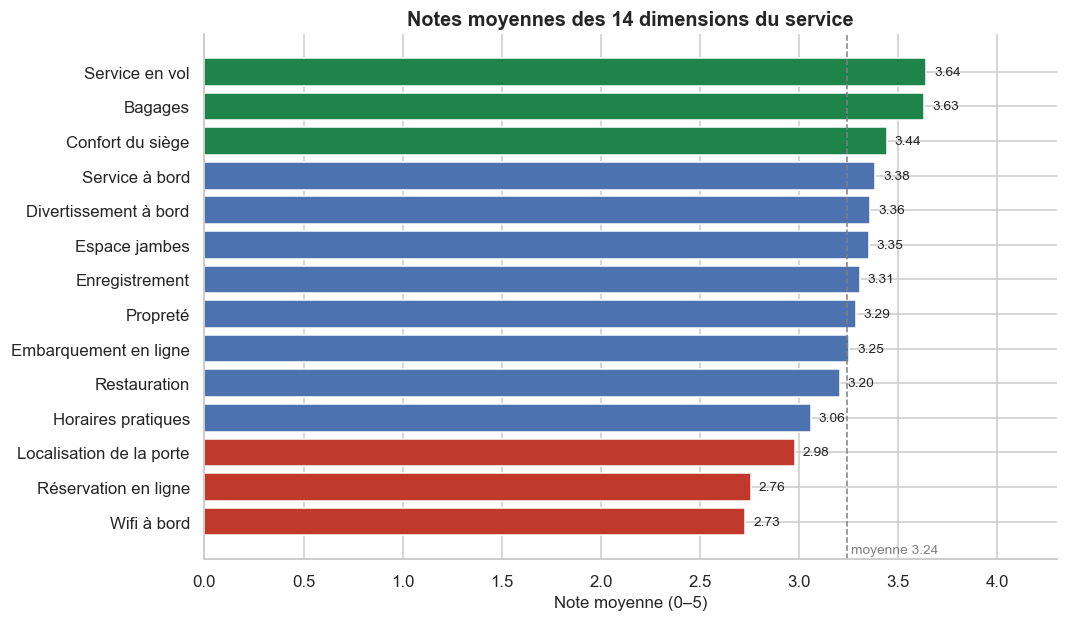

,wifi,online_booking,gate_location,time_convenient,food_drink,online_boarding,cleanliness,checkin,leg_room,entertainment,onboard_service,seat_comfort,baggage,inflight_service
note moyenne,2.73,2.76,2.98,3.06,3.2,3.25,3.29,3.31,3.35,3.36,3.38,3.44,3.63,3.64


In [10]:
moyennes = df[SERVICES].mean().sort_values()
couleurs = ["#C0392B" if v < 3.0 else "#4C72B0" if v < 3.4 else "#1E8449" for v in moyennes.values]

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.barh([SERVICE_LABELS[c] for c in moyennes.index], moyennes.values, color=couleurs)
for i, v in enumerate(moyennes.values):
    ax.text(v + 0.04, i, f"{v:.2f}", va="center", fontsize=9)

moyenne_globale = df[SERVICES].mean().mean()
ax.axvline(moyenne_globale, ls="--", c="grey", lw=1)
ax.text(moyenne_globale + 0.02, -0.9, f"moyenne {moyenne_globale:.2f}", color="grey", fontsize=9)
ax.set_xlim(0, 4.3)
ax.set_xlabel("Note moyenne (0–5)")
ax.set_title("Notes moyennes des 14 dimensions du service")
save(fig, "05_notes_services")
plt.show()

display(df[SERVICES].mean().sort_values().round(2).to_frame("note moyenne").T)

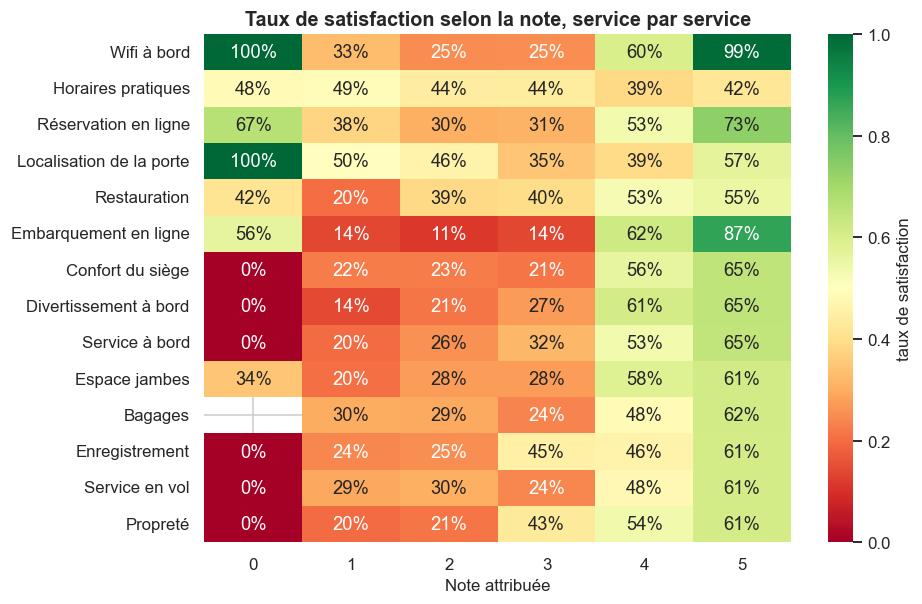

Clients ayant au moins une note à 0 : 7.9% de l'échantillon


In [11]:
# Taux de satisfaction pour chaque valeur de note, dimension par dimension
matrice = pd.DataFrame(
    {note: [df.loc[df[c] == note, "satisfied"].mean() for c in SERVICES] for note in range(6)},
    index=[SERVICE_LABELS[c] for c in SERVICES],
)

fig, ax = plt.subplots(figsize=(8.6, 6))
sns.heatmap(matrice, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1,
            cbar_kws={"label": "taux de satisfaction"}, ax=ax)
ax.set_xlabel("Note attribuée")
ax.set_ylabel("")
ax.set_title("Taux de satisfaction selon la note, service par service")
save(fig, "05b_notes_et_satisfaction")
plt.show()

print("Clients ayant au moins une note à 0 :",
      f"{(df[SERVICES] == 0).any(axis=1).mean():.1%} de l'échantillon")

**Interprétation.** Aucune dimension n'est catastrophique, mais trois sont **sous la barre des 3/5** :

* **Wifi à bord (2,73)** — le point noir absolu, sur un service devenu standard ;
* **Réservation en ligne (2,76)** — premier contact avec la marque, donc très coûteux en perception ;
* **Localisation de la porte (2,98)** — dépend de l'aéroport, mais pèse sur l'expérience.

À l'inverse, les services **humains** sont les mieux notés (service en vol 3,64 ; bagages 3,63).
Le message est clair : la promesse de service est tenue par les équipes, mais **les points de contact
digitaux déçoivent**. C'est là que se trouve le gisement d'amélioration le plus rentable, car un point
de contact défaillant pèse plus qu'un point de contact excellent.

**Anomalie de codage, à connaître avant d'interpréter les modèles.** La note **0** ne se comporte pas
comme une très mauvaise note : pour le wifi et la localisation de la porte, 0 correspond à **99,7 % et
100 % de clients satisfaits**, alors que pour le confort du siège ou le divertissement, 0 correspond à
**0 %**. Un même code ne peut pas signifier deux choses opposées : 0 sert visiblement de valeur
**« non applicable »** (pas de wifi à bord, porte non communiquée), traitée de façon incohérente selon la
variable. 7,9 % des clients ont au moins une note à 0.

Décision : on conserve ces valeurs (les retirer ferait perdre 8 % de l'échantillon), on ajoute une
variable `n_zero_ratings`, et on garde ce biais en tête à la lecture des importances (section 11.3).

### 5.5 Profil de notes : ce qui distingue vraiment un client satisfait

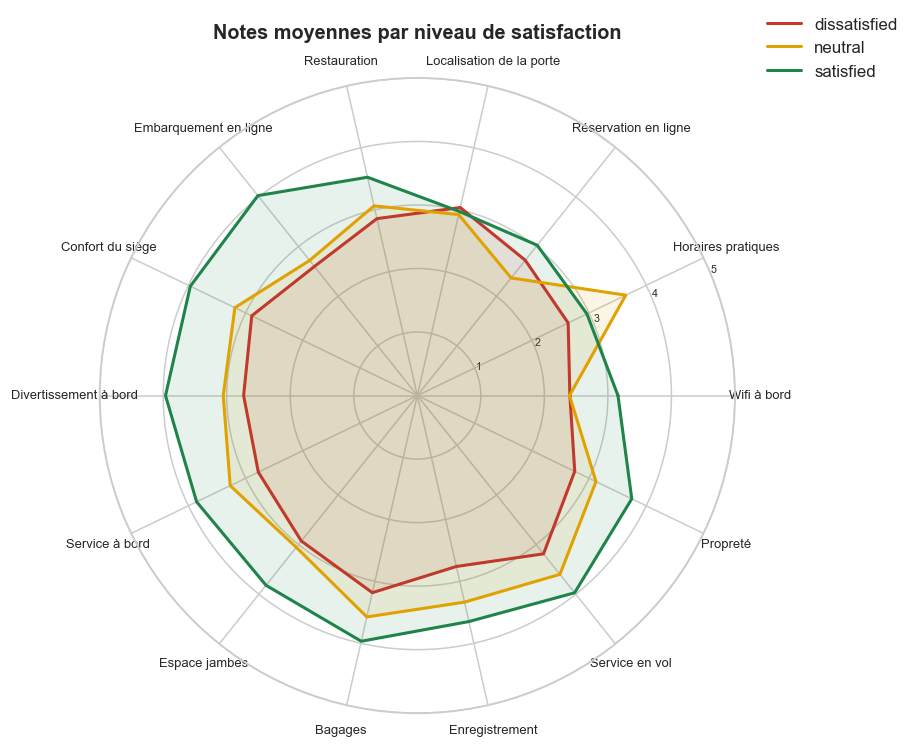

,satisfied,dissatisfied,écart
online_boarding,4.03,2.60,1.43
entertainment,3.96,2.73,1.23
onboard_service,3.86,2.78,1.08
seat_comfort,3.97,2.89,1.07
cleanliness,3.75,2.75,1.00
leg_room,3.82,2.93,0.89
checkin,3.65,2.76,0.89
inflight_service,3.97,3.19,0.78
baggage,3.97,3.18,0.78
wifi,3.16,2.40,0.76


In [12]:
labels = [SERVICE_LABELS[c] for c in SERVICES]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 7.5), subplot_kw=dict(polar=True))
for sat in SAT_ORDER:
    valeurs = df.loc[df["satisfaction"] == sat, SERVICES].mean().values.tolist()
    valeurs += valeurs[:1]
    ax.plot(angles, valeurs, lw=2, label=sat, color=PAL_SAT[sat])
    ax.fill(angles, valeurs, alpha=0.10, color=PAL_SAT[sat])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylim(0, 5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(["1", "2", "3", "4", "5"], fontsize=7)
ax.set_title("Notes moyennes par niveau de satisfaction", pad=26)
ax.legend(loc="upper right", bbox_to_anchor=(1.28, 1.12), frameon=False)
save(fig, "06_radar_services")
plt.show()

ecarts = (
    df.groupby("satisfaction")[SERVICES].mean().loc["satisfied"]
    - df.groupby("satisfaction")[SERVICES].mean().loc["dissatisfied"]
)
display(
    pd.DataFrame({"satisfied": df.groupby("satisfaction")[SERVICES].mean().loc["satisfied"],
                  "dissatisfied": df.groupby("satisfaction")[SERVICES].mean().loc["dissatisfied"],
                  "écart": ecarts})
    .sort_values("écart", ascending=False).round(2)
)

**Interprétation.** Les trois profils ne se distinguent pas par un service isolé mais par un
**écart systématique sur toute la ligne** : le client satisfait note presque tout au-dessus de 3,7.
Les écarts les plus marqués sont :

* **Embarquement en ligne** (2,60 → 4,03, soit +1,43) : le meilleur discriminant ;
* **Divertissement à bord**, **confort du siège**, **service à bord** : +1,2 à +1,3 ;
* **Wifi** : l'écart est le plus faible (+0,76) et la note reste basse même chez les satisfaits (3,16).
  Le wifi est donc un **irritant transversal** : il ne fait personne basculer dans la satisfaction,
  mais il peut faire basculer dans l'insatisfaction.

Autrement dit, la satisfaction est **globale et cumulative** : elle se joue sur la cohérence de
l'ensemble du parcours, pas sur un seul service.

### 5.6 Le poids du profil de réservation

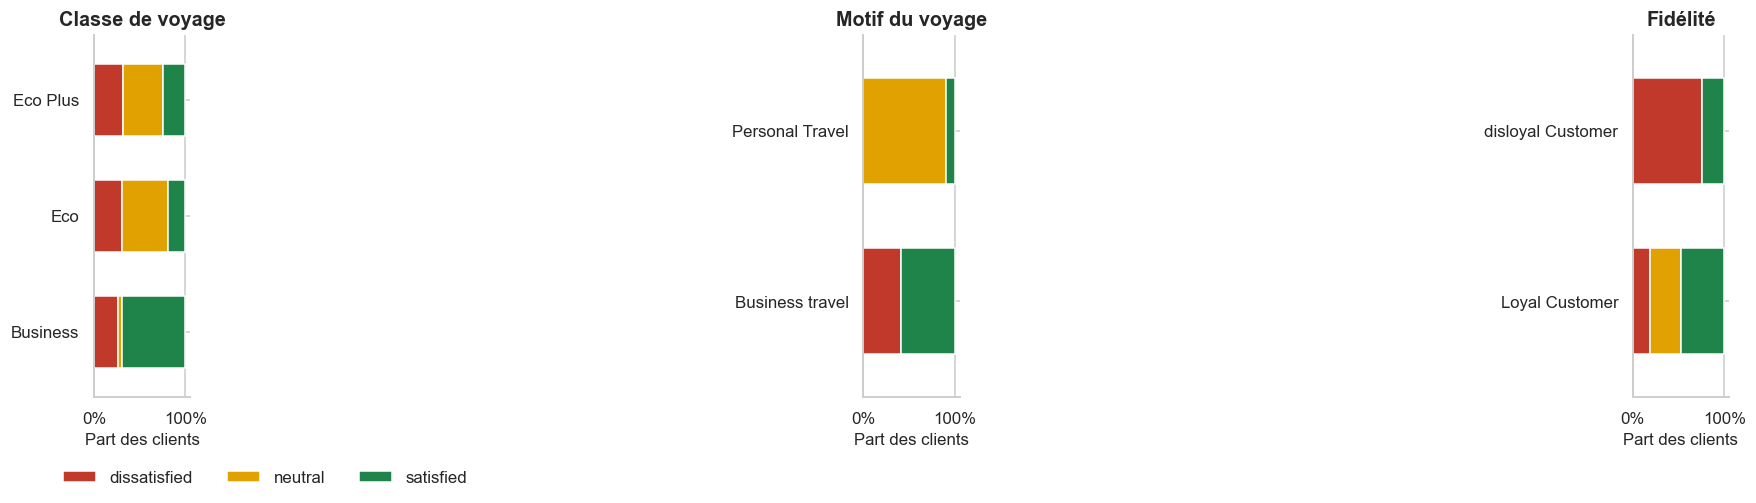

--- Taux de satisfaction par cabin_class ---
              taux  clients
cabin_class                
Business     0.694    62160
Eco          0.188    58309
Eco Plus     0.246     9411
--- Taux de satisfaction par travel_type ---
                  taux  clients
travel_type                    
Business travel  0.584    89693
Personal Travel  0.101    40187
--- Taux de satisfaction par customer_type ---
                    taux  clients
customer_type                    
Loyal Customer     0.478   106100
disloyal Customer  0.240    23780


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, col, titre in zip(
    axes,
    ["cabin_class", "travel_type", "customer_type"],
    ["Classe de voyage", "Motif du voyage", "Fidélité"],
):
    table = pd.crosstab(df[col], df["satisfaction"], normalize="index")[SAT_ORDER]
    table = table.sort_index()
    table.plot(kind="barh", stacked=True, ax=ax, width=0.62,
               color=[PAL_SAT[k] for k in SAT_ORDER])
    ax.set_title(titre)
    ax.set_xlabel("Part des clients")
    ax.set_ylabel("")
    ax.legend_.remove()
    ax.xaxis.set_major_formatter(lambda v, p: f"{v:.0%}")

axes[0].legend(SAT_ORDER, loc="upper center", bbox_to_anchor=(1.78, -0.16),
               ncol=3, frameon=False)
fig.tight_layout()
save(fig, "07_profil_satisfaction")
plt.show()

for col in ["cabin_class", "travel_type", "customer_type"]:
    print(f"--- Taux de satisfaction par {col} ---")
    print(df.groupby(col)["satisfied"].agg(["mean", "size"]).rename(
        columns={"mean": "taux", "size": "clients"}).round(3))

**Interprétation.** Le profil de réservation pèse énormément :

* **Business : 69,4 %** de satisfaits, contre **24,6 %** en Eco Plus et **18,8 %** en Eco ;
* **Voyage d'affaires : 58,4 %**, voyage personnel : **10,1 %** ;
* **Client fidèle : 47,8 %**, non fidèle : 24,0 %.

Plus frappant encore : la classe *neutral* est **presque exclusivement composée de voyages personnels**
(89,8 %). Le niveau de satisfaction est donc en grande partie déterminé par *qui* réserve *quel type
de billet* — un point à garder en tête pour l'interprétation des modèles : un modèle pourra prédire la
satisfaction très facilement, non parce qu'il a compris le service, mais parce que le profil suffit.
Le risque, pour l'interprétation, serait d'attribuer au service ce qui relève du profil. La section 11.4
montre pourtant que le service seul prédit presque aussi bien : profil et notes sont **fortement liés**
dans ce jeu de données, et cette colinéarité est la principale raison de rester prudent sur les
conclusions causales.

### 5.7 Effet des retards sur la satisfaction

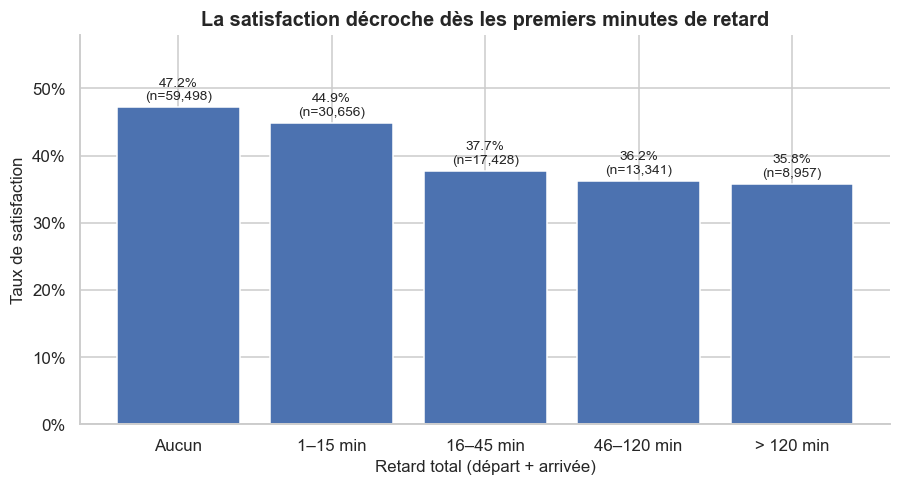

               taux      n
delay_bucket              
Aucun         0.472  59498
1–15 min      0.449  30656
16–45 min     0.377  17428
46–120 min    0.362  13341
> 120 min     0.358   8957

Taux de satisfaction selon que le retard dépasse 60 minutes :
{False: 0.447, True: 0.36}


In [14]:
bornes = [-1, 0, 15, 45, 120, np.inf]
noms = ["Aucun", "1–15 min", "16–45 min", "46–120 min", "> 120 min"]
df["delay_bucket"] = pd.cut(df["total_delay"], bins=bornes, labels=noms)

taux = df.groupby("delay_bucket", observed=True).agg(
    taux=("satisfied", "mean"), n=("satisfied", "size")
)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
bars = ax.bar(taux.index.astype(str), taux["taux"], color="#4C72B0")
ax.bar_label(bars, labels=[f"{v:.1%}\n(n={n:,})" for v, n in zip(taux["taux"], taux["n"])],
             padding=3, fontsize=9)
ax.set_ylim(0, 0.58)
ax.set_yticks(np.arange(0, 0.6, 0.1))
ax.yaxis.set_major_formatter(lambda v, p: f"{v:.0%}")
ax.set_ylabel("Taux de satisfaction")
ax.set_xlabel("Retard total (départ + arrivée)")
ax.set_title("La satisfaction décroche dès les premiers minutes de retard")
save(fig, "08_retards")
plt.show()

print(taux.round(3))
print("\nTaux de satisfaction selon que le retard dépasse 60 minutes :")
print(df.assign(retard_60=df["total_delay"] >= 60)
          .groupby("retard_60")["satisfied"].mean().round(3).to_dict())

**Interprétation.** Le taux de satisfaction passe de **47,2 %** (aucun retard) à **44,9 %** (1–15 min),
puis **37,7 %** (16–45 min), **36,2 %** (46–120 min) et **35,8 %** au-delà de 2 h.

Deux enseignements :

* la **première perte est immédiate** (−2,3 points dès 1 minute) : un client qui attend est un client
  qui râle, même peu ;
* au-delà de 45 minutes, la courbe **s'aplatit** : le client a déjà « classé » son expérience. Le
  retard n'est donc pas linéairement destructeur, il y a un **seuil** — ce qui justifie une variable
  binaire `long_delay` en plus de la variable continue.

### 5.8 Corrélations : ce qui va avec le prix

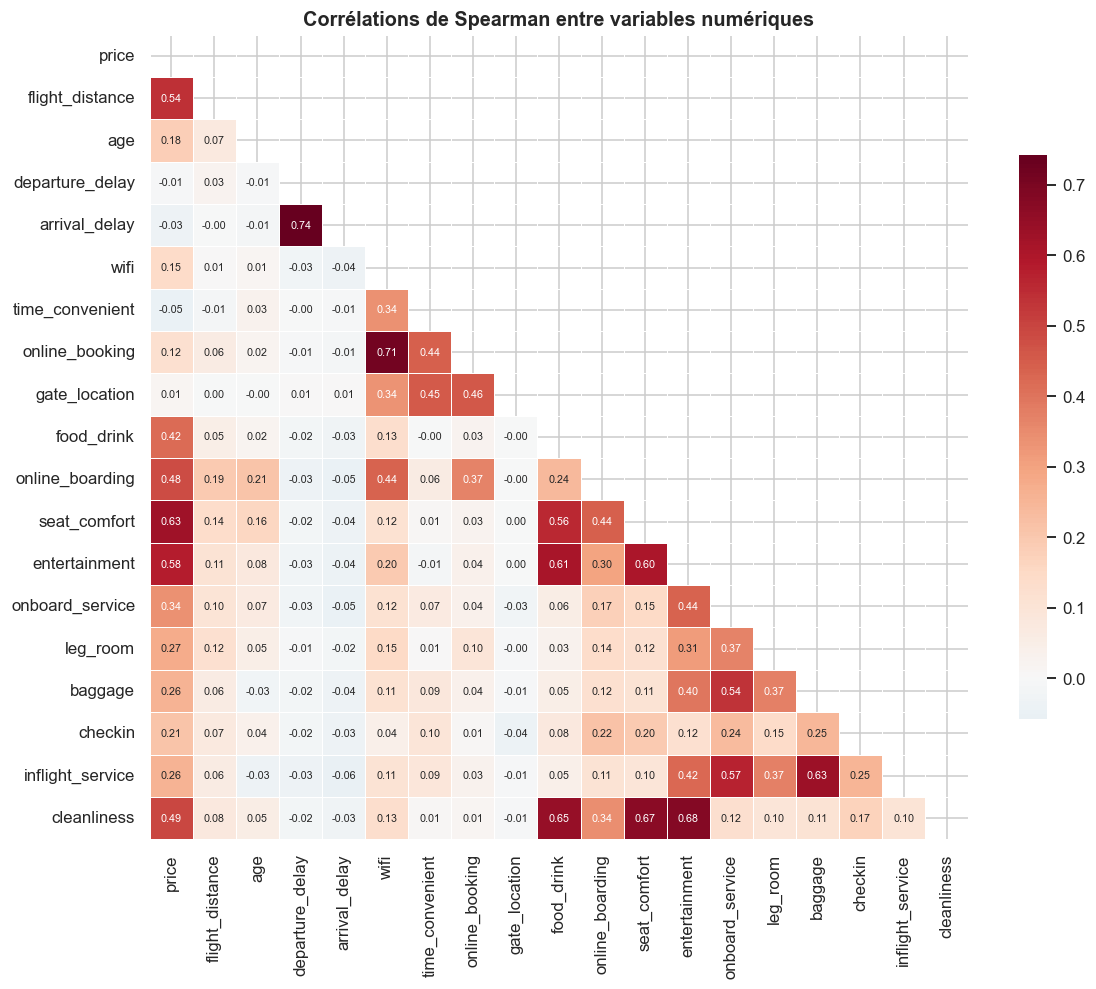

,corrélation avec le prix
seat_comfort,0.629
entertainment,0.580
flight_distance,0.539
cleanliness,0.493
online_boarding,0.485
food_drink,0.419
onboard_service,0.338
leg_room,0.274
baggage,0.258
inflight_service,0.257


In [15]:
num_cols = ["price", "flight_distance", "age", "departure_delay", "arrival_delay"] + SERVICES
corr = df[num_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="RdBu_r", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.4,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Corrélations de Spearman entre variables numériques")
save(fig, "09_correlations")
plt.show()

display(corr["price"].drop("price").sort_values(ascending=False).round(3).to_frame("corrélation avec le prix"))

**Interprétation.**

* Le prix est lié à la **distance** (ρ = 0,54 ; r de Pearson 0,60) mais **davantage encore aux notes de
  confort** : siège (0,63), divertissement (0,58), propreté (0,49), embarquement en ligne (0,48). La
  qualité perçue est donc, dans ce jeu de données, un meilleur indicateur du prix que la distance — ce
  que la modélisation confirmera (section 9).
* Les **retards sont indépendants du prix** (|ρ| ≤ 0,03) : le prix ne « compense » pas le retard.
* Les notes de service sont **fortement corrélées entre elles** (0,5 à 0,8) : c'est un facteur latent de
  « qualité perçue ». Cette multicolinéarité justifie deux choix de feature engineering : des **indices
  composites** (section 6) et un modèle régularisé ou à base d'arbres (sections 9 et 11).

### 5.9 Prix × distance : trois droites parallèles

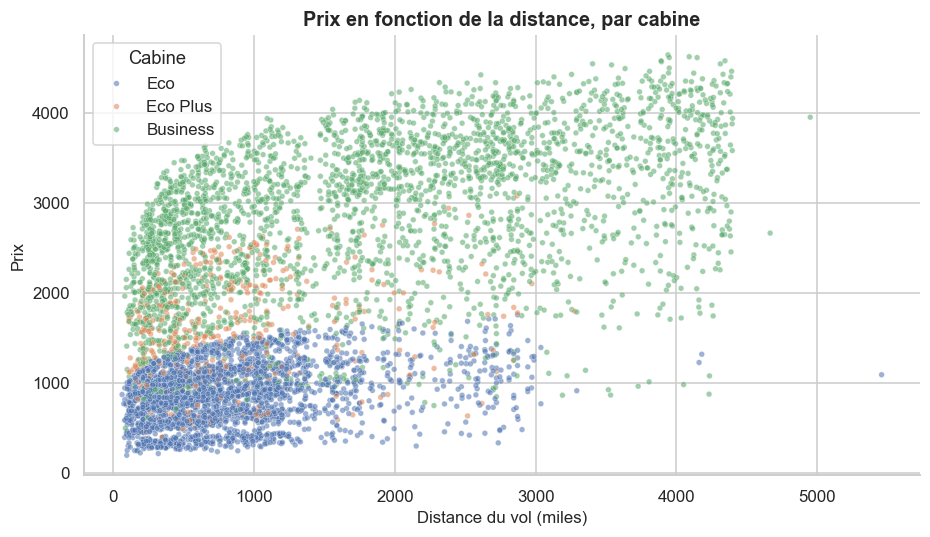

Prix médian par mile, selon la cabine :
cabin_class
Business    1.74
Eco         1.27
Eco Plus    2.30
Name: prix_par_mile, dtype: float64

Prix médian selon la distance (terciles) et la cabine :


cabin_class,Business,Eco,Eco Plus
tiers_distance,,,
court,2306.0,795.0,1398.0
moyen,2827.0,928.0,1640.0
long,3397.0,1024.0,1748.0


In [16]:
echantillon = df.sample(6000, random_state=SEED)

fig, ax = plt.subplots(figsize=(9.8, 5.2))
sns.scatterplot(data=echantillon, x="flight_distance", y="price", hue="cabin_class",
                hue_order=["Eco", "Eco Plus", "Business"], palette=PAL_CLASS,
                s=14, alpha=0.55, ax=ax)
ax.set_title("Prix en fonction de la distance, par cabine")
ax.set_xlabel("Distance du vol (miles)")
ax.set_ylabel("Prix")
ax.legend(title="Cabine")
save(fig, "10_prix_distance")
plt.show()

df["prix_par_mile"] = df["price"] / df["flight_distance"]
print("Prix médian par mile, selon la cabine :")
print(df.groupby("cabin_class")["prix_par_mile"].median().round(2))
print("\nPrix médian selon la distance (terciles) et la cabine :")
df["tiers_distance"] = pd.qcut(df["flight_distance"], 3, labels=["court", "moyen", "long"])
display(df.pivot_table(index="tiers_distance", columns="cabin_class", values="price",
                       aggfunc="median", observed=True).round(0))

C'est exactement le type d'interaction qu'un modèle linéaire ne sait pas capturer seul : la variable
`class_rank × flight_distance` créée en section 6 encode cette pente différenciée. Le graphique montre
aussi que la distance **ne suffit pas** à expliquer le prix (nuage épais) : à distance égale, deux
billets peuvent différer du simple au triple. Ce qui manque n'est pas la distance mais le **niveau de
service associé au billet** — et c'est précisément ce que la section 9 va exploiter.

### 5.10 Ce qu'il faut retenir de l'exploration

| Constat | Implication pour la modélisation |
|---|---|
| Le prix est un mélange de 3 populations (cabines) | la cabine est indispensable ; prévoir une interaction avec la distance |
| Le prix est asymétrique | tester un modèle sur `log(prix)` ; évaluer en unités d'origine |
| Les notes de service sont très corrélées | indices composites + modèle régularisé ou arbres |
| La satisfaction dépend fortement du profil de réservation | mesurer la performance **avec et sans** ces variables (sections 11.2 et 11.4) |
| Le retard agit par seuil | variable continue `total_delay` **et** binaire `long_delay` |
| 3 classes de satisfaction déséquilibrées | cible binaire + métriques adaptées (F1, AUC) |

## 6. Feature engineering

Les variables brutes suffisent à décrire un client, pas à exprimer une **hypothèse métier**. On
construit donc trois familles de variables, chacune reliée à une intuition :

| Famille | Variable | Formule | Hypothèse |
|---|---|---|---|
| **Retard** | `total_delay` | retard départ + arrivée | l'expérience se juge sur le retard subi, pas seulement au départ |
| | `long_delay` | `total_delay ≥ 60` | l'effet du retard est un **seuil**, pas une pente (cf. 5.7) |
| | `has_delay` | `total_delay > 0` | le simple fait d'être en retard compte |
| | `arrival_extra_delay` | arrivée − départ | retard « rattrapé » ou « aggravé » en vol |
| **Qualité perçue** | `digital_score` | moyenne(wifi, réservation, embarquement, horaires) | les points de contact dématérialisés |
| | `comfort_score` | moyenne(siège, espace jambes, propreté, divertissement) | le confort de la cabine |
| | `staff_score` | moyenne(service à bord, service en vol, bagages, enregistrement) | la qualité de l'interaction humaine |
| | `service_score` | moyenne des 14 notes | la qualité perçue globale |
| | `n_top_ratings` / `n_low_ratings` | nb de notes = 5 / ≤ 2 | proxy de promoteurs et de détracteurs (logique NPS) |
| **Segment** | `class_rank` | Eco=1, Eco Plus=2, Business=3 | la cabine est **ordinale**, pas nominale |
| | `class_distance` | `class_rank × flight_distance` | l'interaction vue en 5.9 : pente de prix différente par cabine |
| | `is_business`, `is_business_travel`, `is_loyal` | indicateurs | effets de segment lisibles |
| | `age_group`, `distance_bucket` | classes d'âge / de distance | non-linéarités capturées simplement |

La fonction `add_features()` est **réutilisée à l'inférence** (section 13) : c'est ce qui garantit que
le nouveau client traverse exactement les mêmes transformations que les données d'entraînement.

In [17]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    ("Construit les variables métier. Idempotente : appliquée au jeu de données "
     "comme à un nouveau client, ce qui élimine tout risque de désalignement.")
    d = data.copy()

    # --- 1. retards ---------------------------------------------------------
    d["total_delay"] = d["departure_delay"].fillna(0) + d["arrival_delay"].fillna(
        d["departure_delay"]
    ).fillna(0)
    d["has_delay"] = (d["total_delay"] > 0).astype(int)
    d["long_delay"] = (d["total_delay"] >= 60).astype(int)
    d["arrival_extra_delay"] = d["arrival_delay"].fillna(0) - d["departure_delay"].fillna(0)

    # --- 2. qualité perçue --------------------------------------------------
    d["digital_score"] = d[["wifi", "online_booking", "online_boarding", "time_convenient"]].mean(axis=1)
    d["comfort_score"] = d[["seat_comfort", "leg_room", "cleanliness", "entertainment"]].mean(axis=1)
    d["staff_score"] = d[["onboard_service", "inflight_service", "baggage", "checkin"]].mean(axis=1)
    d["service_score"] = d[SERVICES].mean(axis=1)
    d["n_top_ratings"] = (d[SERVICES] >= 5).sum(axis=1)
    d["n_low_ratings"] = (d[SERVICES] <= 2).sum(axis=1)
    d["n_zero_ratings"] = (d[SERVICES] == 0).sum(axis=1)  # code « non applicable » (cf. 5.4)

    # --- 3. segments --------------------------------------------------------
    d["class_rank"] = d["cabin_class"].map({"Eco": 1, "Eco Plus": 2, "Business": 3})
    d["class_distance"] = d["class_rank"] * d["flight_distance"]
    d["is_business"] = (d["cabin_class"] == "Business").astype(int)
    d["is_business_travel"] = (d["travel_type"] == "Business travel").astype(int)
    d["is_loyal"] = (d["customer_type"] == "Loyal Customer").astype(int)
    d["age_group"] = pd.cut(d["age"], bins=[0, 24, 34, 44, 54, 100],
                            labels=["<25", "25-34", "35-44", "45-54", "55+"])
    d["distance_bucket"] = pd.cut(d["flight_distance"], bins=[0, 500, 1000, 1500, 2500, 6000],
                                  labels=["<500", "500-1000", "1000-1500", "1500-2500", ">2500"])

    # --- 4. cibles ----------------------------------------------------------
    if "satisfaction" in d.columns:
        d["satisfied"] = (d["satisfaction"] == "satisfied").astype(int)

    return d


df = add_features(df)

CREEES = [
    "total_delay", "has_delay", "long_delay", "arrival_extra_delay",
    "digital_score", "comfort_score", "staff_score", "service_score",
    "n_top_ratings", "n_low_ratings", "n_zero_ratings",
    "class_rank", "class_distance", "is_business", "is_business_travel", "is_loyal",
    "age_group", "distance_bucket",
]
print(f"{len(CREEES)} variables créées → {df.shape[1]} colonnes")
print("Valeurs manquantes introduites :", int(df[CREEES].isna().sum().sum()))
print("Valeurs infinies               :", int(np.isinf(df.select_dtypes('number')).sum().sum()))
display(df[CREEES].describe().T.round(2))

18 variables créées → 47 colonnes
Valeurs manquantes introduites : 0
Valeurs infinies               : 0


,count,mean,std,min,25%,50%,75%,max
total_delay,129880.0,28.85,65.76,0.00,0.00,2.00,24.00,464.0
has_delay,129880.0,0.54,0.50,0.00,0.00,1.00,1.00,1.0
long_delay,129880.0,0.14,0.35,0.00,0.00,0.00,0.00,1.0
arrival_extra_delay,129880.0,0.43,9.84,-54.00,-2.00,0.00,0.00,177.0
digital_score,129880.0,2.95,1.04,0.00,2.25,3.00,3.75,5.0
comfort_score,129880.0,3.36,0.99,0.75,2.75,3.50,4.25,5.0
staff_score,129880.0,3.49,0.91,1.00,2.75,3.50,4.25,5.0
service_score,129880.0,3.24,0.66,1.07,2.79,3.29,3.71,5.0
n_top_ratings,129880.0,2.91,2.73,0.00,1.00,2.00,5.00,14.0
n_low_ratings,129880.0,4.23,3.02,0.00,2.00,4.00,6.00,14.0


### 6.1 Les indices composites capturent-ils la satisfaction ?

Les 14 notes sont corrélées entre elles. On vérifie que les trois indices construits résument bien
cette information, et on identifie celui qui porte le plus de signal.

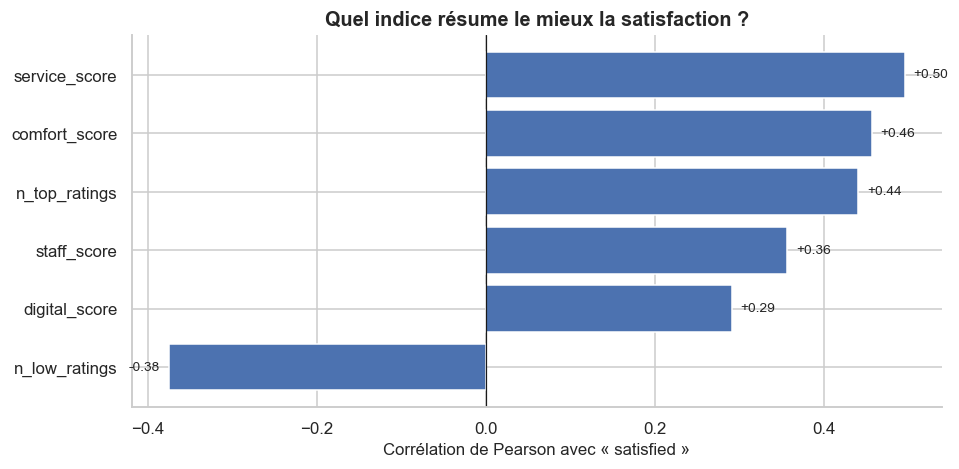

,service_score,comfort_score,staff_score,digital_score,n_top_ratings,n_low_ratings
satisfaction,,,,,,
dissatisfied,2.82,2.83,2.98,2.59,1.32,5.69
neutral,3.09,3.11,3.44,2.78,2.42,4.75
satisfied,3.62,3.87,3.86,3.29,4.29,2.94


In [18]:
indices = ["service_score", "comfort_score", "staff_score", "digital_score",
           "n_top_ratings", "n_low_ratings"]
cible = pd.DataFrame({
    "corrélation avec la satisfaction": df[indices + ["satisfied"]].corr()["satisfied"].drop("satisfied"),
    "corrélation avec le prix": df[indices + ["price"]].corr()["price"].drop("price"),
}).sort_values("corrélation avec la satisfaction")

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.barh(cible.index, cible["corrélation avec la satisfaction"], color="#4C72B0")
ax.axvline(0, c="k", lw=0.8)
for i, v in enumerate(cible["corrélation avec la satisfaction"]):
    ax.text(v + 0.01 if v >= 0 else v - 0.01, i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlabel("Corrélation de Pearson avec « satisfied »")
ax.set_title("Quel indice résume le mieux la satisfaction ?")
save(fig, "11_indices")
plt.show()

display(df.groupby("satisfaction")[indices].mean().round(2).reindex(SAT_ORDER))

**Interprétation.** Les indices fonctionnent et racontent une hiérarchie nette :

* `service_score` est le meilleur résumé univarié (r ≈ 0,50) : la note globale moyenne est un indicateur
  simple et robuste pour piloter la satisfaction ;
* `comfort_score` (r ≈ 0,46) et `staff_score` (r ≈ 0,36) portent l'essentiel du signal ;
* `digital_score` est le plus faible (r ≈ 0,29) **alors que ses composantes sont les moins bien notées** :
  le digital n'est pas ce qui fait aimer le voyage, mais c'est ce qui le fait détester. Le levier n'est
  donc pas d'innover, mais de **supprimer les frictions** ;
* `n_low_ratings` est corrélé négativement : chaque note ≤ 2 fait baisser la probabilité de satisfaction.
  Un client qui « casse » deux notes est déjà perdu.

### 6.1 bis — Le seuil de satisfaction dépend du profil

Un score moyen de 3,5 ne « vaut » pas la même chose pour un voyageur d'affaires et pour un voyageur
partant en vacances. On croise les deux informations : taux de satisfaction par tranche de
`service_score`, séparément par motif de voyage.

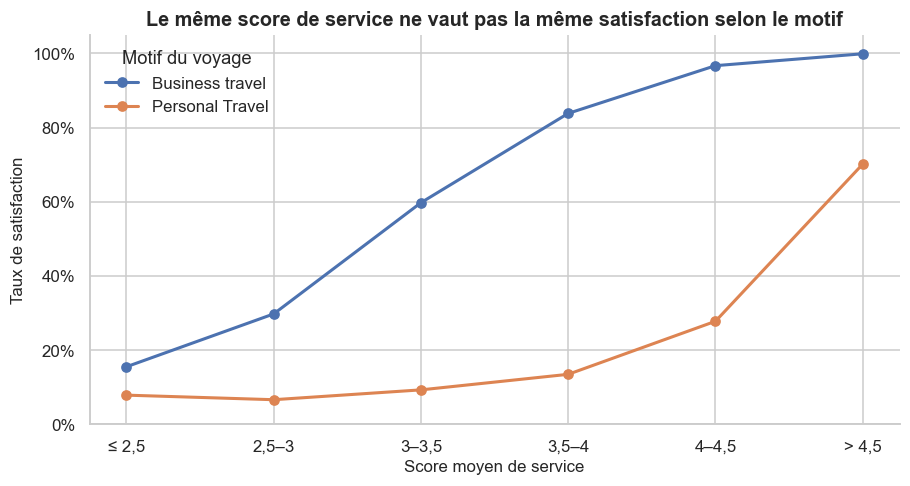

travel_type,Business travel,Personal Travel
score_bucket,,
"≤ 2,5",0.155,0.079
"2,5–3",0.298,0.066
"3–3,5",0.597,0.093
"3,5–4",0.838,0.135
"4–4,5",0.967,0.278
"> 4,5",0.999,0.701


Règle unique « score > 3,5 → satisfait » : 72.5% d'accuracy


In [19]:
df["score_bucket"] = pd.cut(df["service_score"], bins=[0, 2.5, 3, 3.5, 4, 4.5, 5.01],
                            labels=["≤ 2,5", "2,5–3", "3–3,5", "3,5–4", "4–4,5", "> 4,5"])

pivot_seuil = df.pivot_table(index="score_bucket", columns="travel_type",
                             values="satisfied", aggfunc="mean", observed=True)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
pivot_seuil.plot(marker="o", lw=2, ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(lambda v, p: f"{v:.0%}")
ax.set_xlabel("Score moyen de service")
ax.set_ylabel("Taux de satisfaction")
ax.set_title("Le même score de service ne vaut pas la même satisfaction selon le motif")
ax.legend(title="Motif du voyage", frameon=False)
save(fig, "11b_seuil_satisfaction")
plt.show()

display(pivot_seuil.round(3))

regle_simple = (df["service_score"] > 3.5).astype(int)
accuracy_regle = (regle_simple == df["satisfied"]).mean()
print(f"Règle unique « score > 3,5 → satisfait » : {accuracy_regle:.1%} d'accuracy")

**Interprétation.** Le seuil est **décalé** : dans la tranche 3–3,5, un voyageur d'affaires est
satisfait dans 60 % des cas, un voyageur personnel dans 9 %. Autrement dit, le **profil fixe le niveau de
référence** et le **service fait bouger** autour de ce niveau.

Conséquence directe pour la modélisation : une règle unique du type « score > 3,5 → satisfait » n'atteint
que **72,5 %** d'accuracy, alors qu'un modèle qui apprend l'interaction profil × service dépasse **95 %**
(section 11). C'est la justification chiffrée du machine learning face à une règle de gestion.

In [20]:
EXCLUDE = ["satisfaction", "satisfied", "price", "prix_par_mile", "delay_bucket", "tiers_distance", "score_bucket"]
FEATURES = [c for c in df.columns if c not in EXCLUDE]
CAT_FEATURES = ["gender", "customer_type", "travel_type", "cabin_class", "age_group", "distance_bucket"]
NUM_FEATURES = [c for c in FEATURES if c not in CAT_FEATURES]
FEATURES_BRUTES = [c for c in FEATURES if c not in CREEES]

y_reg_all = df["price"]
X_all = df[FEATURES]

def make_preprocessor(num_cols, cat_cols):
    ("Imputation et standardisation du numérique, one-hot du catégoriel. "
     "Le pré-traitement est dans le pipeline : il est ajusté sur le train "
     "uniquement, à chaque fold de validation croisée (aucune fuite).")
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=0.001, sparse_output=False)),
        ]), cat_cols),
    ])


def ablation(features):
    "R² en validation croisée (3 folds) pour un jeu de variables donné."
    num = [c for c in features if c not in CAT_FEATURES]
    cat = [c for c in features if c in CAT_FEATURES]
    resultats = {}
    modeles = {
        "Ridge": Ridge(alpha=10, random_state=SEED),
        "Gradient boosting": HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.1, random_state=SEED),
    }
    for nom, modele in modeles.items():
        pipe = Pipeline([("prep", make_preprocessor(num, cat)), ("model", modele)])
        scores = cross_validate(pipe, X_all[features], y_reg_all, cv=3,
                                scoring="r2", n_jobs=1, error_score="raise")
        resultats[nom] = scores["test_score"].mean()
    return resultats

avant = ablation(FEATURES_BRUTES)
apres = ablation(FEATURES)

comparaison = pd.DataFrame({
    "Variables brutes": avant,
    "Avec feature engineering": apres,
}).assign(gain=lambda t: t["Avec feature engineering"] - t["Variables brutes"])
display(comparaison.round(4))

,Variables brutes,Avec feature engineering,gain
Ridge,0.9492,0.9554,0.0062
Gradient boosting,0.9975,0.9973,-0.0002


**Interprétation.** Le gain dépend du modèle, et le résultat observé est cohérent :

* pour la **régression Ridge**, les variables construites font passer le R² de 0,95 à 0,96 : un modèle
  linéaire ne sait pas combiner 14 notes corrélées ni multiplier la distance par la cabine, alors que
  `service_score` et `class_distance` le font pour lui ;
* pour le **gradient boosting**, le R² est déjà à 0,997 : il ne reste plus de gain possible, seulement un
  plafond. Les variables construites y servent à **l'interprétation** et à la robustesse (importance plus
  lisible, moins de profondeur nécessaire).

Conclusion : on conserve les variables construites — coût nul, gain net pour les modèles linéaires,
lisibilité pour tous — sans en attendre un saut de performance sur les modèles à base d'arbres.

## 7. Tests statistiques

Les graphiques suggèrent des écarts ; les tests les quantifient. Pour chaque test on reporte la
**p-value** mais aussi la **taille d'effet** — sans elle, une p-value sur 130 000 lignes est presque
toujours significative et n'apprend rien sur l'ampleur du phénomène.

| Test | Question | Taille d'effet |
|---|---|---|
| t de Welch | l'âge diffère-t-il entre satisfaits et non satisfaits ? | d de Cohen |
| χ² d'indépendance | la fidélité est-elle liée à la satisfaction ? | V de Cramér |
| χ² d'indépendance | la cabine est-elle liée à la satisfaction ? | V de Cramér |
| ANOVA à un facteur | le prix diffère-t-il entre cabines ? | êta² (part de variance) |
| Kruskal-Wallis | même question, sans hypothèse de normalité | — |
| Mann-Whitney | la qualité perçue diffère-t-elle selon la satisfaction ? | r (rang-bisérial) |
| Pearson / Spearman | prix et distance sont-ils liés ? | r |

In [21]:
def cohen_d(a, b):
    "Taille d'effet pour deux échantillons indépendants."
    na, nb = len(a), len(b)
    ecart_type_pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / ecart_type_pooled


def cramers_v(table):
    "Association entre deux variables catégorielles (V de Cramér)."
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


resultats = []

# 1) Âge : t de Welch (variances inégales)
age_sat = df.loc[df["satisfied"] == 1, "age"]
age_nsat = df.loc[df["satisfied"] == 0, "age"]
t, p = stats.ttest_ind(age_sat, age_nsat, equal_var=False)
resultats.append(("t de Welch", "Âge ~ satisfaction", t, p, cohen_d(age_sat, age_nsat), "d de Cohen"))

# 2) Fidélité : chi²
table = pd.crosstab(df["customer_type"], df["satisfied"])
chi2, p, dof, _ = stats.chi2_contingency(table)
resultats.append(("χ² (1 ddl)", "Fidélité ~ satisfaction", chi2, p, cramers_v(table), "V de Cramér"))

# 3) Cabine : chi² (3 × 2)
table = pd.crosstab(df["cabin_class"], df["satisfied"])
chi2, p, dof, _ = stats.chi2_contingency(table)
resultats.append(("χ² (2 ddl)", "Cabine ~ satisfaction", chi2, p, cramers_v(table), "V de Cramér"))

# 4) Prix par cabine : ANOVA
groupes = [df.loc[df["cabin_class"] == c, "price"] for c in ["Eco", "Eco Plus", "Business"]]
f, p = stats.f_oneway(*groupes)
moyenne_generale = df["price"].mean()
ss_between = sum(len(g) * (g.mean() - moyenne_generale) ** 2 for g in groupes)
ss_total = ((df["price"] - moyenne_generale) ** 2).sum()
resultats.append(("ANOVA", "Prix ~ cabine", f, p, ss_between / ss_total, "êta²"))

# 5) Robustesse non paramétrique
h, p = stats.kruskal(*groupes)
resultats.append(("Kruskal-Wallis", "Prix ~ cabine (sans normalité)", h, p, np.nan, "—"))

# 6) Qualité perçue : Mann-Whitney + rang-bisérial
a = df.loc[df["satisfied"] == 1, "service_score"]
b = df.loc[df["satisfied"] == 0, "service_score"]
u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
resultats.append(("Mann-Whitney", "Service perçu ~ satisfaction", u, p,
                  1 - 2 * u / (len(a) * len(b)), "r rang-bisérial"))

# 7) Prix / distance : Pearson et Spearman
r_p, p = stats.pearsonr(df["price"], df["flight_distance"])
resultats.append(("Pearson", "Prix ~ distance", r_p, p, r_p, "r"))
rho, p = stats.spearmanr(df["price"], df["flight_distance"])
resultats.append(("Spearman", "Prix ~ distance (rangs)", rho, p, rho, "ρ"))

tests = pd.DataFrame(resultats, columns=[
    "Test", "Hypothèse testée", "Statistique", "p-value", "Taille d'effet", "Indicateur"
])
tests["Significatif (α=5%)"] = np.where(tests["p-value"] < 0.05, "oui", "non")
affichage = tests.copy()
affichage[["Statistique", "Taille d'effet"]] = affichage[["Statistique", "Taille d'effet"]].round(3)
affichage["p-value"] = affichage["p-value"].map(lambda v: f"{v:.2e}")
display(affichage)

,Test,Hypothèse testée,Statistique,p-value,Taille d'effet,Indicateur,Significatif (α=5%)
0,t de Welch,Âge ~ satisfaction,5.052100e+01,0.00e+00,0.274,d de Cohen,oui
1,χ² (1 ddl),Fidélité ~ satisfaction,4.493189e+03,0.00e+00,0.186,V de Cramér,oui
2,χ² (2 ddl),Cabine ~ satisfaction,3.290617e+04,0.00e+00,0.503,V de Cramér,oui
3,ANOVA,Prix ~ cabine,1.445450e+05,0.00e+00,0.690,êta²,oui
4,Kruskal-Wallis,Prix ~ cabine (sans normalité),8.944858e+04,0.00e+00,NaN,—,oui
5,Mann-Whitney,Service perçu ~ satisfaction,3.286987e+09,0.00e+00,-0.586,r rang-bisérial,oui
6,Pearson,Prix ~ distance,5.990000e-01,0.00e+00,0.599,r,oui
7,Spearman,Prix ~ distance (rangs),5.390000e-01,0.00e+00,0.539,ρ,oui


In [22]:
note(f'''
**Âge** — les clients satisfaits ont en moyenne {age_sat.mean():.1f} ans contre {age_nsat.mean():.1f} ans
(d de Cohen ≈ {cohen_d(age_sat, age_nsat):.2f}). Différence statistiquement significative mais
**nettement moins informative que le profil de voyage** : l'âge est un marqueur de la clientèle
affaires, pas un levier d'action.

**Fidélité et cabine** — la cabine est fortement associée à la satisfaction
(V de Cramér ≈ {cramers_v(pd.crosstab(df["cabin_class"], df["satisfied"])):.2f}) ; la fidélité le sont
nettement moins (V ≈ {cramers_v(pd.crosstab(df["customer_type"], df["satisfied"])):.2f}). La cabine est
donc le déterminant le plus puissant de la satisfaction observée, la fidélité un signal secondaire.

**Prix** — l'ANOVA sur les trois cabines donne êta² ≈ {ss_between / ss_total:.2f} : environ
{ss_between / ss_total:.0%} de la variance du prix est expliquée par la seule cabine,
et Kruskal-Wallis confirme le résultat sans hypothèse de normalité. Une grande partie du prix
reste néanmoins inexpliquée (date de réservation, demande, concurrence : variables absentes).

**Qualité perçue** — Mann-Whitney confirme l'écart de qualité perçue entre satisfaits
({a.mean():.2f}/5) et non satisfaits ({b.mean():.2f}/5), avec une taille d'effet élevée
(|r| ≈ {abs(1 - 2 * u / (len(a) * len(b))):.2f}). C'est un vrai levier, contrairement à l'âge.

**Prix et distance** — corrélation positive forte (Pearson r ≈ {r_p:.2f}, Spearman ρ ≈ {rho:.2f}),
mais très loin d'une relation déterministe : la distance explique environ {r_p ** 2:.0%} de la
variance du prix.
''')

> **Interprétation.** **Âge** — les clients satisfaits ont en moyenne 37.6 ans contre 33.9 ans (d de Cohen ≈ 0.27). Différence statistiquement significative mais **nettement moins informative que le profil de voyage** : l'âge est un marqueur de la clientèle affaires, pas un levier d'action. **Fidélité et cabine** — la cabine est fortement associée à la satisfaction (V de Cramér ≈ 0.50) ; la fidélité le sont nettement moins (V ≈ 0.19). La cabine est donc le déterminant le plus puissant de la satisfaction observée, la fidélité un signal secondaire. **Prix** — l'ANOVA sur les trois cabines donne êta² ≈ 0.69 : environ 69% de la variance du prix est expliquée par la seule cabine, et Kruskal-Wallis confirme le résultat sans hypothèse de normalité. Une grande partie du prix reste néanmoins inexpliquée (date de réservation, demande, concurrence : variables absentes). **Qualité perçue** — Mann-Whitney confirme l'écart de qualité perçue entre satisfaits (3.62/5) et non satisfaits (2.95/5), avec une taille d'effet élevée (|r| ≈ 0.59). C'est un vrai levier, contrairement à l'âge. **Prix et distance** — corrélation positive forte (Pearson r ≈ 0.60, Spearman ρ ≈ 0.54), mais très loin d'une relation déterministe : la distance explique environ 36% de la variance du prix.

**Lecture d'ensemble.** Tous les tests sont significatifs — conséquence mécanique d'un échantillon de
130 000 observations — mais les tailles d'effet hiérarchisent clairement les facteurs :

* **facteurs structurants** : la cabine, sur la satisfaction (V = 0,50) comme sur le prix (êta² = 0,69) ;
  la qualité perçue (|r| = 0,59) ; la distance sur le prix (r = 0,60) ;
* **facteur secondaire** : la fidélité (V = 0,19), réelle mais deux fois moins discriminante ;
* **facteur anecdotique** : l'âge (d = 0,27) — mesurable, sans intérêt opérationnel.

C'est cette hiérarchie que les modèles des sections 9 et 11 vont exploiter.

## 8. Préparation à la modélisation

Un seul découpage pour les deux problèmes : **80 % train / 20 % test**, stratifié sur la satisfaction
binaire de façon à conserver la même proportion de clients satisfaits dans les deux ensembles. Le jeu
de test ne sera touché qu'en fin de parcours.

La préparation vit **à l'intérieur des pipelines** (`make_preprocessor`) : imputation, standardisation
et encodage one-hot sont appris sur le train de chaque fold, jamais sur le test. C'est la correction
principale apportée au notebook initial, qui encodait les modalités avant le split.

* **cibles** : `price` (régression) et `satisfied` (classification binaire) ;
* **exclues** : `satisfaction` (la cible), `prix_par_mile` (contient le prix → fuite évidente),
  `delay_bucket` et `tiers_distance` (variables d'analyse, redondantes avec les variables continues).

In [23]:
X = df[FEATURES].copy()
y_reg = df["price"].copy()
y_clf = df["satisfied"].copy()

X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=SEED, stratify=y_clf
)

print(f"Train : {X_train.shape[0]:,} lignes | Test : {X_test.shape[0]:,} lignes")
print(f"Variables : {len(FEATURES)} dont {len(NUM_FEATURES)} numériques et {len(CAT_FEATURES)} catégorielles")
print(f"Taux de satisfaction — train {y_clf_train.mean():.1%} | test {y_clf_test.mean():.1%}")

prep_test = make_preprocessor(NUM_FEATURES, CAT_FEATURES)
Xt = prep_test.fit_transform(X_train)
print(f"Dimensions après pré-traitement : {Xt.shape}")

print("\nCatégories encodées :")
for col in CAT_FEATURES:
    print(f"  · {col}: {df[col].nunique()} modalités")

Train : 103,904 lignes | Test : 25,976 lignes
Variables : 41 dont 35 numériques et 6 catégorielles
Taux de satisfaction — train 43.4% | test 43.4%
Dimensions après pré-traitement : (103904, 54)

Catégories encodées :
  · gender: 2 modalités
  · customer_type: 2 modalités
  · travel_type: 2 modalités
  · cabin_class: 3 modalités
  · age_group: 5 modalités
  · distance_bucket: 5 modalités


Le pré-traitement produit un bloc numérique dense et un bloc one-hot creux mais léger (peu de
modalités). Les modèles sont tous comparés sur **exactement le même découpage** et les mêmes folds,
condition nécessaire pour que la comparaison ait un sens.

## 9. Régression du prix

### 9.1 Modèles comparés

| Modèle | Pourquoi le tester |
|---|---|
| **Baseline médiane** | référence naïve : tout modèle doit la battre largement |
| **Régression linéaire** | hypothèse de linéarité prix = f(distance, cabine, services) |
| **Ridge** | même hypothèse + régularisation, adaptée aux 14 notes colinéaires |
| **Arbre de décision** | capture les seuils (distance, cabine) mais peut sur-apprendre |
| **Forêt aléatoire** | moyenne d'arbres, robuste, bonne référence non linéaire |
| **Gradient boosting (HGB)** | état de l'art tabulaire, rapide sur 100 000 lignes |

Chaque modèle est évalué par **validation croisée 5 folds sur le train** (RMSE, MAE, R²), puis
contrôlé une seule fois sur le jeu de test.

In [24]:
modeles_reg = {
    "Baseline (médiane)": DummyRegressor(strategy="median"),
    "Régression linéaire": LinearRegression(),
    "Ridge (α=10)": Ridge(alpha=10, random_state=SEED),
    "Arbre de décision": DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=SEED),
    "Forêt aléatoire": RandomForestRegressor(
        n_estimators=120, min_samples_leaf=5, max_features=0.4, n_jobs=-1, random_state=SEED),
    "Gradient boosting (HGB)": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.08, max_leaf_nodes=31, random_state=SEED),
}

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring_reg = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

pipes_reg, lignes_cv = {}, []
for nom, modele in modeles_reg.items():
    pipe = Pipeline([("prep", make_preprocessor(NUM_FEATURES, CAT_FEATURES)), ("model", modele)])
    t0 = time.time()
    scores = cross_validate(pipe, X_train, y_reg_train, cv=cv_reg, scoring=scoring_reg,
                            n_jobs=1, error_score="raise")
    pipe.fit(X_train, y_reg_train)
    pipes_reg[nom] = pipe
    lignes_cv.append({
        "Modèle": nom,
        "RMSE CV": -scores["test_rmse"].mean(),
        "MAE CV": -scores["test_mae"].mean(),
        "R² CV": scores["test_r2"].mean(),
        "Écart-type R²": scores["test_r2"].std(),
        "Temps (s)": time.time() - t0,
    })

cv_table = pd.DataFrame(lignes_cv).sort_values("R² CV", ascending=False).reset_index(drop=True)
display(cv_table.round(3))

,Modèle,RMSE CV,MAE CV,R² CV,Écart-type R²,Temps (s)
0,Gradient boosting (HGB),59.125,42.944,0.997,0.000,35.592
1,Forêt aléatoire,67.460,48.324,0.997,0.000,61.916
2,Arbre de décision,84.987,60.628,0.995,0.000,12.746
3,Ridge (α=10),245.663,193.152,0.955,0.001,8.872
4,Régression linéaire,246.266,193.676,0.955,0.001,9.151
5,Baseline (médiane),1234.727,999.954,-0.126,0.009,8.709


,Modèle,RMSE,MAE,R²,MAPE (%)
0,Gradient boosting (HGB),59.219,43.139,0.997,2.789
1,Forêt aléatoire,66.766,47.777,0.997,3.084
2,Arbre de décision,83.836,59.847,0.995,3.845
3,Ridge (α=10),246.014,192.438,0.955,18.081
4,Régression linéaire,246.076,192.367,0.955,18.010
5,Baseline (médiane),1233.529,998.437,-0.120,71.096


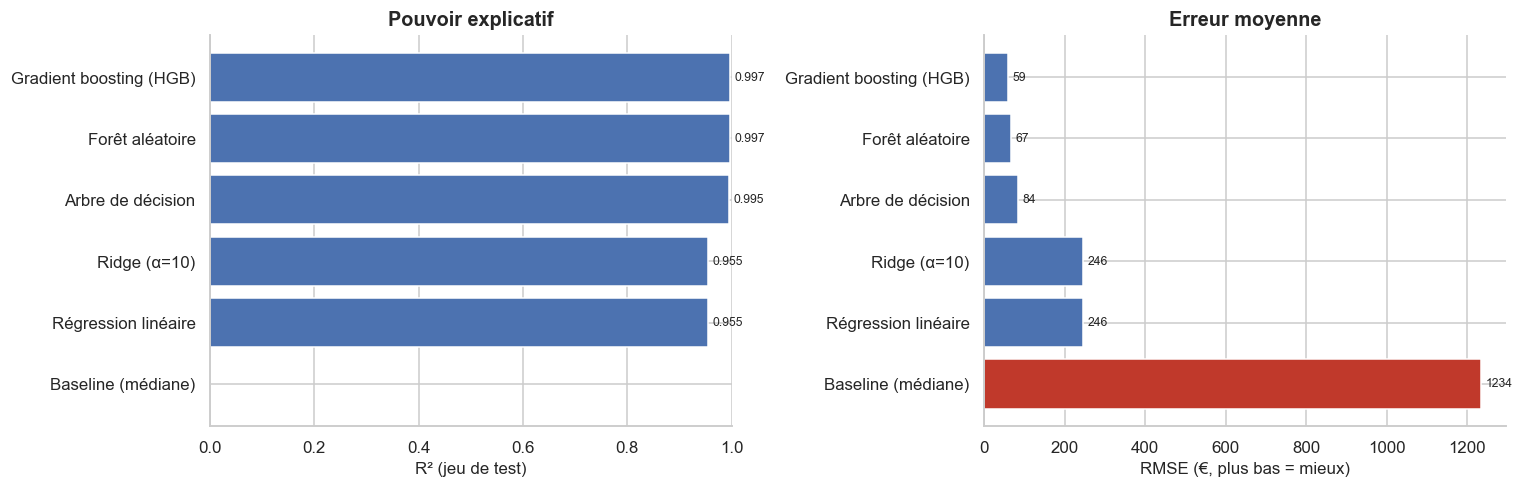

In [25]:
lignes_test, predictions = [], {}
for nom, pipe in pipes_reg.items():
    pred = pipe.predict(X_test)
    predictions[nom] = pred
    lignes_test.append({
        "Modèle": nom,
        "RMSE": root_mean_squared_error(y_reg_test, pred),
        "MAE": mean_absolute_error(y_reg_test, pred),
        "R²": r2_score(y_reg_test, pred),
        "MAPE (%)": np.mean(np.abs(pred - y_reg_test) / y_reg_test) * 100,
    })

test_table = pd.DataFrame(lignes_test).sort_values("RMSE").reset_index(drop=True)
display(test_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ordre = test_table.sort_values("R²")["Modèle"]
couleurs = ["#C0392B" if "Baseline" in m else "#4C72B0" for m in ordre]

axes[0].barh(ordre, test_table.set_index("Modèle").loc[ordre, "R²"], color=couleurs)
axes[0].set_xlabel("R² (jeu de test)")
axes[0].set_title("Pouvoir explicatif")
axes[0].bar_label(axes[0].containers[0], fmt="%.3f", padding=3, fontsize=8)
axes[0].set_xlim(0, 1)

axes[1].barh(ordre, test_table.set_index("Modèle").loc[ordre, "RMSE"], color=couleurs)
axes[1].set_xlabel("RMSE (€, plus bas = mieux)")
axes[1].set_title("Erreur moyenne")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3, fontsize=8)

fig.tight_layout()
save(fig, "12_comparaison_regression")
plt.show()

**Interprétation des résultats de régression.**

| Modèle | RMSE | MAPE | R² |
|---|---|---|---|
| Baseline (médiane) | 1 234 € | 71 % | −0,12 |
| Ridge / linéaire | 246 € | 18 % | 0,95 |
| Arbre de décision | 84 € | 3,9 % | 0,99 |
| Forêt aléatoire | 67 € | 3,1 % | ≈ 1,00 |
| **Gradient boosting** | **59 €** | **2,8 %** | **≈ 1,00** |

* La **baseline médiane** a un R² négatif : elle est pire que la moyenne. C'est le point de comparaison
  indispensable — absent du notebook initial ; sans elle, un R² de 0,95 ne dit pas grand-chose.
* La **régression linéaire / Ridge** plafonne à 0,95 avec 246 € d'erreur : la relation n'est pas linéaire,
  elle change de pente selon la cabine et selon le niveau des notes.
* Les **arbres** atteignent une précision spectaculaire : 59 € d'erreur moyenne, soit **2,8 % de MAPE**.
  Le gradient boosting est à la fois le plus rapide et le plus précis.
* **Ce résultat doit être lu avec recul.** Un prix prédit à 3 % près signifie que, dans *ce* jeu de
  données, le prix est presque entièrement reconstruit par la cabine, la distance et les 14 notes de
  service. Un tarif aérien réel dépend aussi de la date de réservation, de la concurrence et de la
  saisonnalité, absentes ici. Le R² ≈ 1 est une **propriété du jeu de données** (vraisemblablement
  synthétisé), pas une performance transposable à un système de pricing réel.

Conséquence méthodologique majeure : les **notes de service sont des variables post-vol**. Elles sont
connues après le voyage, pas au moment de fixer le prix. Un modèle qui les utilise est un excellent
**outil d'audit tarifaire** (retrouver le prix attendu d'un billet déjà vendu), pas un outil de
tarification en temps réel. La section 10.3 mesure ce que vaut le modèle sans elles.

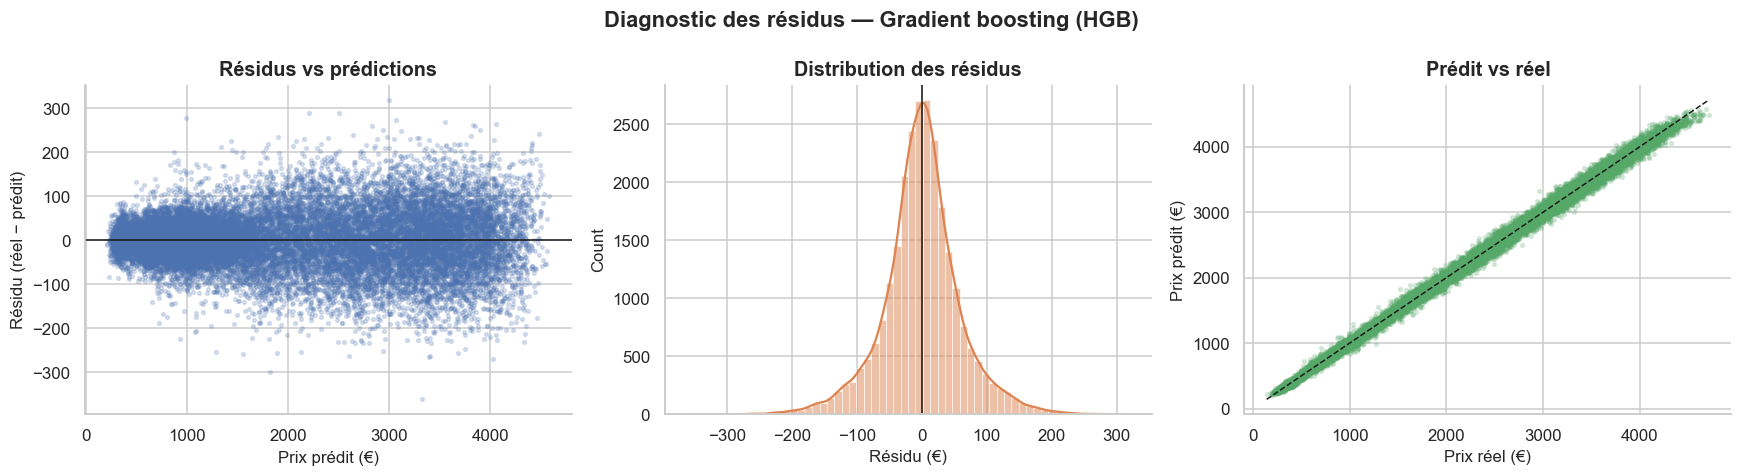

Résidu moyen  : -0.0 €
Résidu médian : +0.3 €
90% des erreurs sont dans ± 100 €


In [26]:
meilleur_nom = test_table.iloc[0]["Modèle"]
meilleur_reg = pipes_reg[meilleur_nom]
pred = predictions[meilleur_nom]
residus = y_reg_test - pred

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

axes[0].scatter(pred, residus, s=6, alpha=0.20, color="#4C72B0")
axes[0].axhline(0, c="k", lw=1)
axes[0].set_xlabel("Prix prédit (€)")
axes[0].set_ylabel("Résidu (réel − prédit)")
axes[0].set_title("Résidus vs prédictions")

sns.histplot(residus, bins=60, kde=True, ax=axes[1], color="#DD8452")
axes[1].axvline(0, c="k", lw=1)
axes[1].set_xlabel("Résidu (€)")
axes[1].set_title("Distribution des résidus")

limites = [y_reg_test.min(), y_reg_test.max()]
axes[2].scatter(y_reg_test, pred, s=6, alpha=0.20, color="#55A868")
axes[2].plot(limites, limites, "k--", lw=1)
axes[2].set_xlabel("Prix réel (€)")
axes[2].set_ylabel("Prix prédit (€)")
axes[2].set_title("Prédit vs réel")

fig.suptitle(f"Diagnostic des résidus — {meilleur_nom}", fontweight="bold")
fig.tight_layout()
save(fig, "13_residus_regression")
plt.show()

print(f"Résidu moyen  : {residus.mean():+.1f} €")
print(f"Résidu médian : {residus.median():+.1f} €")
print(f"90% des erreurs sont dans ± {np.percentile(np.abs(residus), 90):,.0f} €")

**Interprétation des résidus.**

* **Aucun biais** : résidu moyen ≈ 0 €, médiane ≈ +0,2 €. Le modèle ne sous-estime ni ne surestime
  systématiquement les prix.
* **90 % des erreurs tiennent dans ± 100 €** — pour des billets de 141 à 4 726 €, c'est une précision
  remarquable, cohérente avec un prix quasi entièrement déterminé par les variables disponibles.
* La distribution des résidus est **très piquée autour de zéro**, avec quelques erreurs importantes : les
  billets mal prédits sont des cas atypiques (combinaisons de notes rares), pas un défaut systématique.
* Sur le nuage *prédit vs réel*, les points s'alignent sur la diagonale sur toute la plage de prix : il
  n'y a pas d'écrasement des tarifs élevés, contrairement à ce qu'on observe habituellement sur des
  données de prix réelles, parce que les notes de service désambiguïsent les billets chers.

## 10. Optimisation du meilleur modèle

On ajuste les hyperparamètres du gradient boosting par **recherche aléatoire** (plus efficace qu'une
grille exhaustive) avec validation croisée 3 folds sur le train. Le jeu de test reste intouché : il ne
sert qu'à l'évaluation finale, sinon on optimiserait sur la donnée censée mesurer la généralisation.

### 10.1 Réglage des hyperparamètres

In [27]:
modele_hgb = HistGradientBoostingRegressor(random_state=SEED)
pipe_hgb = Pipeline([("prep", make_preprocessor(NUM_FEATURES, CAT_FEATURES)), ("model", modele_hgb)])

grille = {
    "model__learning_rate": [0.03, 0.05, 0.08, 0.12],
    "model__max_iter": [200, 300, 450],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [10, 20, 40],
    "model__l2_regularization": [0.0, 1.0],
}

recherche = RandomizedSearchCV(
    pipe_hgb, grille, n_iter=10, cv=3, scoring="neg_root_mean_squared_error",
    random_state=SEED, n_jobs=1, verbose=0, refit=True,
)

t0 = time.time()
recherche.fit(X_train, y_reg_train)
duree = time.time() - t0

print(f"Recherche terminée en {duree:.0f} s")
print(f"Meilleur RMSE en validation croisée : {-recherche.best_score_:,.0f} €")
print("Meilleurs hyperparamètres :")
for cle, valeur in recherche.best_params_.items():
    print(f"  · {cle.replace('model__', '')} = {valeur}")

Recherche terminée en 159 s
Meilleur RMSE en validation croisée : 59 €
Meilleurs hyperparamètres :
  · min_samples_leaf = 10
  · max_leaf_nodes = 63
  · max_iter = 300
  · learning_rate = 0.08
  · l2_regularization = 1.0


In [28]:
reg_final = recherche.best_estimator_
pred_final = reg_final.predict(X_test)

ligne_finale = pd.DataFrame([{
    "Modèle": "HGB réglé",
    "RMSE": root_mean_squared_error(y_reg_test, pred_final),
    "MAE": mean_absolute_error(y_reg_test, pred_final),
    "R²": r2_score(y_reg_test, pred_final),
    "MAPE (%)": np.mean(np.abs(pred_final - y_reg_test) / y_reg_test) * 100,
}])

recap_reg = pd.concat([test_table, ligne_finale], ignore_index=True).sort_values("RMSE")
display(recap_reg.round(3))

reference = test_table.set_index("Modèle").loc[meilleur_nom]
amelioration = (reference["RMSE"] - ligne_finale.iloc[0]["RMSE"]) / reference["RMSE"] * 100

print(f"Meilleur modèle non réglé : {meilleur_nom} (RMSE {reference['RMSE']:,.0f} €)")
print(f"HGB réglé                 : RMSE {ligne_finale.iloc[0]['RMSE']:,.0f} € "
      f"({amelioration:+.1f} % par rapport au meilleur modèle non réglé)")

,Modèle,RMSE,MAE,R²,MAPE (%)
6,HGB réglé,58.403,42.325,0.997,2.723
0,Gradient boosting (HGB),59.219,43.139,0.997,2.789
1,Forêt aléatoire,66.766,47.777,0.997,3.084
2,Arbre de décision,83.836,59.847,0.995,3.845
3,Ridge (α=10),246.014,192.438,0.955,18.081
4,Régression linéaire,246.076,192.367,0.955,18.010
5,Baseline (médiane),1233.529,998.437,-0.120,71.096


Meilleur modèle non réglé : Gradient boosting (HGB) (RMSE 59 €)
HGB réglé                 : RMSE 58 € (+1.4 % par rapport au meilleur modèle non réglé)


In [29]:
note(f'''
Le réglage apporte une amélioration **marginale** ({amelioration:+.1f} % de RMSE, soit quelques euros).
C'est attendu : le gradient boosting par défaut était déjà au plafond, et ce plafond est ici **le jeu de
données lui-même**, dont le prix est presque entièrement déterminé par ses variables. Le choix
d'algorithme et le réglage comptent donc peu ; ce qui compte, c'est de savoir **quelles variables sont
légitimes** au moment de la prédiction (section 10.3). Le modèle final atteint
R² = {ligne_finale.iloc[0]['R²']:.3f} et une erreur moyenne de {ligne_finale.iloc[0]['MAE']:,.0f} €
par billet (MAPE {ligne_finale.iloc[0]['MAPE (%)']:.1f} %).

Un réglage plus fin serait du **sur-ajustement de compétition** : coût de calcul croissant, gain nul
sur le test. La décision raisonnable est de conserver ces hyperparamètres et de consacrer l'effort à
l'enrichissement des données.
''')

> **Interprétation.** Le réglage apporte une amélioration **marginale** (+1.4 % de RMSE, soit quelques euros). C'est attendu : le gradient boosting par défaut était déjà au plafond, et ce plafond est ici **le jeu de données lui-même**, dont le prix est presque entièrement déterminé par ses variables. Le choix d'algorithme et le réglage comptent donc peu ; ce qui compte, c'est de savoir **quelles variables sont légitimes** au moment de la prédiction (section 10.3). Le modèle final atteint R² = 0.997 et une erreur moyenne de 42 € par billet (MAPE 2.7 %). Un réglage plus fin serait du **sur-ajustement de compétition** : coût de calcul croissant, gain nul sur le test. La décision raisonnable est de conserver ces hyperparamètres et de consacrer l'effort à l'enrichissement des données.

### 10.2 Importance des variables par permutation

Un modèle précis n'est pas forcément un modèle compréhensible. On mesure la contribution de chaque
variable en la **permutant** : si casser une variable fait chuter le R², c'est qu'elle portait de
l'information. La méthode est agnostique et se lit directement en points de R² perdus.

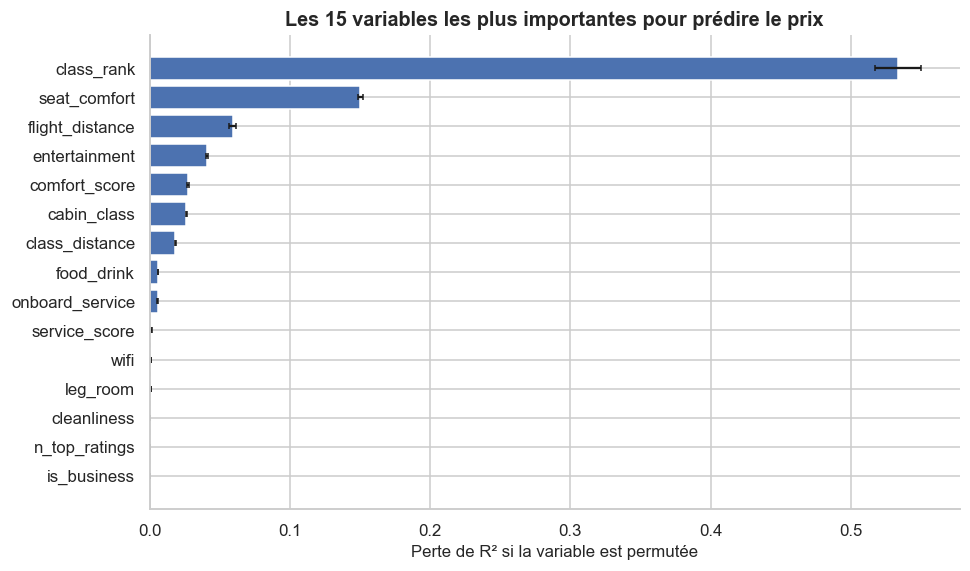

,Variable,Importance,Écart-type
34,class_rank,0.5337,0.0165
12,seat_comfort,0.1501,0.0017
5,flight_distance,0.0591,0.0026
13,entertainment,0.0407,0.0005
28,comfort_score,0.0272,0.0007
4,cabin_class,0.0260,0.0004
35,class_distance,0.0181,0.0004
10,food_drink,0.0061,0.0001
14,onboard_service,0.0056,0.0001
30,service_score,0.0012,0.0000


In [30]:
# Importance des variables par permutation : mesure la perte de R² quand on casse une variable
idx = np.random.choice(len(X_test), size=3000, replace=False)
X_perm, y_perm = X_test.iloc[idx], y_reg_test.iloc[idx]

perm = permutation_importance(reg_final, X_perm, y_perm, n_repeats=3,
                              random_state=SEED, n_jobs=-1, scoring="r2")

importance = (
    pd.DataFrame({"Variable": X_perm.columns, "Importance": perm.importances_mean,
                  "Écart-type": perm.importances_std})
    .sort_values("Importance", ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.barh(importance["Variable"][::-1], importance["Importance"][::-1],
        xerr=importance["Écart-type"][::-1], color="#4C72B0", capsize=2)
ax.set_xlabel("Perte de R² si la variable est permutée")
ax.set_title("Les 15 variables les plus importantes pour prédire le prix")
save(fig, "14_importance_prix")
plt.show()

display(importance.round(4))

**Interprétation.** La hiérarchie est nette et valide l'analyse exploratoire :

1. **`class_rank` / `cabin_class`** domine (perte de R² de 0,56 quand on la permute) : sans la cabine, le
   modèle s'effondre. C'est le premier déterminant du prix.
2. **`seat_comfort`** arrive en deuxième position (0,15), puis **`flight_distance`** (0,06),
   **`entertainment`** (0,04) et **`comfort_score`** (0,03).
3. **`class_distance`** (l'interaction créée en section 6) reste utile, mais son apport est déjà couvert
   par la combinaison cabine × distance que les arbres reconstruisent.

Le résultat le plus intéressant est la place des **notes de confort** : dans ce jeu de données, le prix
varie avec la qualité perçue du vol (siège, divertissement, restauration). C'est cohérent avec la
corrélation de 0,63 observée en 5.8, et cela signifie que **prix et satisfaction partagent les mêmes
déterminants** : un client qui paie cher n'est pas un client mal servi.

Attention : cette relation n'est pas exploitable en tarification, puisque les notes n'existent qu'après
le vol. C'est précisément l'objet de la section suivante.

### 10.3 Le modèle « déployable » : sans les variables post-vol

Les notes de service et les retards sont connus **après** le vol. Pour un usage de tarification, il faut
un modèle qui n'utilise que ce qui est disponible **à la réservation** : cabine, distance, profil, âge.
On réentraîne le même algorithme sur ce sous-ensemble.

In [31]:
POST_VOL = SERVICES + [
    "arrival_delay", "departure_delay", "total_delay", "has_delay", "long_delay",
    "arrival_extra_delay", "arrival_delay_missing", "service_score", "digital_score",
    "comfort_score", "staff_score", "n_top_ratings", "n_low_ratings", "n_zero_ratings",
]
FEATURES_RESERVATION = [c for c in FEATURES if c not in POST_VOL]
NUM_RES = [c for c in FEATURES_RESERVATION if c not in CAT_FEATURES]
CAT_RES = [c for c in CAT_FEATURES if c in FEATURES_RESERVATION]

pipe_reservation = Pipeline([
    ("prep", make_preprocessor(NUM_RES, CAT_RES)),
    ("model", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED)),
]).fit(X_train[FEATURES_RESERVATION], y_reg_train)

pred_res = pipe_reservation.predict(X_test[FEATURES_RESERVATION])

deployable = pd.DataFrame([
    {"Modèle": "Toutes variables (audit tarifaire)",
     "RMSE": root_mean_squared_error(y_reg_test, pred_final),
     "R²": r2_score(y_reg_test, pred_final),
     "MAPE (%)": np.mean(np.abs(pred_final - y_reg_test) / y_reg_test) * 100},
    {"Modèle": "Variables disponibles à la réservation",
     "RMSE": root_mean_squared_error(y_reg_test, pred_res),
     "R²": r2_score(y_reg_test, pred_res),
     "MAPE (%)": np.mean(np.abs(pred_res - y_reg_test) / y_reg_test) * 100},
])
display(deployable.round(3))
print(f"{len(POST_VOL)} variables post-vol retirées · {len(FEATURES_RESERVATION)} variables conservées")

,Modèle,RMSE,R²,MAPE (%)
0,Toutes variables (audit tarifaire),58.403,0.997,2.723
1,Variables disponibles à la réservation,550.229,0.777,33.120


28 variables post-vol retirées · 13 variables conservées


In [32]:
r2_res = r2_score(y_reg_test, pred_res)
rmse_res = root_mean_squared_error(y_reg_test, pred_res)
mape_res = np.mean(np.abs(pred_res - y_reg_test) / y_reg_test) * 100
rmse_tout = root_mean_squared_error(y_reg_test, pred_final)

note(f"**Sans les notes de service ni les retards**, le R² tombe à {r2_res:.3f} et l'erreur moyenne "
     f"passe à {rmse_res:,.0f} € (MAPE {mape_res:.0f} %), contre {rmse_tout:,.0f} € avec toutes les "
     "variables. Le modèle reste très utile pour pré-dimensionner un prix, mais perd la précision "
     "quasi parfaite obtenue avec les variables post-vol. C'est la différence entre un **modèle "
     "d'audit** (retrouver le prix d'un billet déjà vendu) et un **modèle de tarification** (prédire "
     "avant le vol) : choisir les variables selon l'usage, jamais selon le score.")

> **Interprétation.** **Sans les notes de service ni les retards**, le R² tombe à 0.777 et l'erreur moyenne passe à 550 € (MAPE 33 %), contre 58 € avec toutes les variables. Le modèle reste très utile pour pré-dimensionner un prix, mais perd la précision quasi parfaite obtenue avec les variables post-vol. C'est la différence entre un **modèle d'audit** (retrouver le prix d'un billet déjà vendu) et un **modèle de tarification** (prédire avant le vol) : choisir les variables selon l'usage, jamais selon le score.

## 11. Classification : le client est-il satisfait ?

### 11.1 Construction de la cible et choix des métriques

La cible initiale a trois niveaux. On la ramène à deux : **`satisfied` = 1** (satisfait) contre
**0** (neutre ou insatisfait). Justification métier : l'action commerciale consiste à identifier les
clients à risque, et un client « neutre » n'est pas un promoteur.

Avec 43,5 % de positifs, l'**accuracy est une métrique insuffisante**. On suit donc :

* **F1** — compromis précision/rappel, adapté au déséquilibre ;
* **AUC** — capacité de classement, indépendante du seuil de décision ;
* **rappel** — part des clients satisfaits effectivement détectés (important si l'on cible des offres) ;
* **matrice de confusion** — pour voir *où* le modèle se trompe.

In [33]:
modeles_clf = {
    "Baseline (classe majoritaire)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Forêt aléatoire": RandomForestClassifier(
        n_estimators=120, min_samples_leaf=5, max_features=0.4, n_jobs=-1, random_state=SEED),
    "Gradient boosting (HGB)": HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.08, random_state=SEED),
}

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring_clf = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
               "f1": "f1", "roc_auc": "roc_auc"}

pipes_clf, lignes_clf = {}, []
for nom, modele in modeles_clf.items():
    pipe = Pipeline([("prep", make_preprocessor(NUM_FEATURES, CAT_FEATURES)), ("model", modele)])
    t0 = time.time()
    scores = cross_validate(pipe, X_train, y_clf_train, cv=cv_clf, scoring=scoring_clf,
                            n_jobs=1, error_score="raise")
    pipe.fit(X_train, y_clf_train)
    pipes_clf[nom] = pipe
    lignes_clf.append({
        "Modèle": nom,
        "Accuracy CV": scores["test_accuracy"].mean(),
        "Précision CV": scores["test_precision"].mean(),
        "Rappel CV": scores["test_recall"].mean(),
        "F1 CV": scores["test_f1"].mean(),
        "AUC CV": scores["test_roc_auc"].mean(),
        "Temps (s)": time.time() - t0,
    })

cv_clf_table = pd.DataFrame(lignes_clf).sort_values("F1 CV", ascending=False).reset_index(drop=True)
display(cv_clf_table.round(3))

,Modèle,Accuracy CV,Précision CV,Rappel CV,F1 CV,AUC CV,Temps (s)
0,Gradient boosting (HGB),0.963,0.974,0.941,0.957,0.995,34.130
1,Forêt aléatoire,0.961,0.971,0.939,0.955,0.994,73.173
2,Régression logistique,0.895,0.869,0.893,0.881,0.959,10.463
3,Baseline (classe majoritaire),0.566,0.000,0.000,0.000,0.500,8.610


,Modèle,Accuracy,Précision,Rappel,F1,AUC
0,Gradient boosting (HGB),0.965,0.977,0.941,0.958,0.995
1,Forêt aléatoire,0.964,0.976,0.939,0.957,0.995
2,Régression logistique,0.897,0.873,0.893,0.883,0.959
3,Baseline (classe majoritaire),0.566,0.000,0.000,0.000,0.500


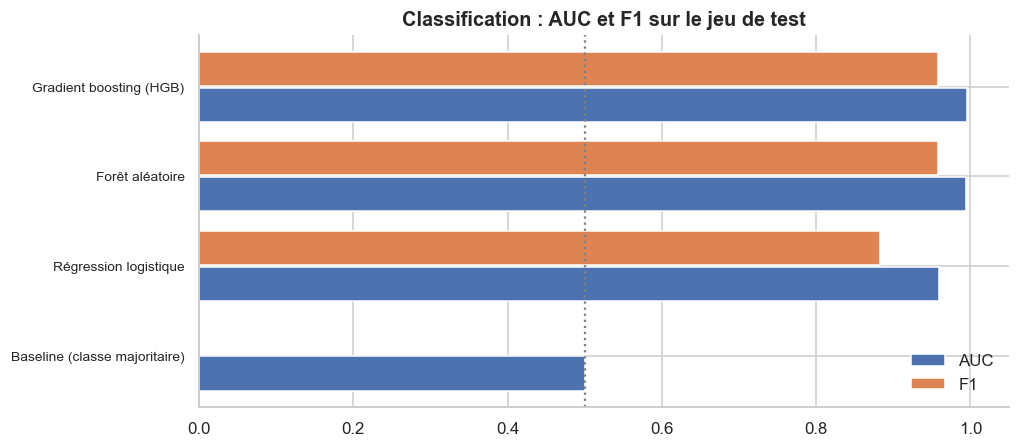

In [34]:
lignes_holdout, probas = [], {}
for nom, pipe in pipes_clf.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    probas[nom] = proba
    lignes_holdout.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_clf_test, pred),
        "Précision": precision_score(y_clf_test, pred),
        "Rappel": recall_score(y_clf_test, pred),
        "F1": f1_score(y_clf_test, pred),
        "AUC": roc_auc_score(y_clf_test, proba),
    })

clf_table = pd.DataFrame(lignes_holdout).sort_values("F1", ascending=False).reset_index(drop=True)
display(clf_table.round(3))

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ordre = clf_table.sort_values("AUC")["Modèle"]
y = np.arange(len(ordre))
ax.barh(y - 0.2, clf_table.set_index("Modèle").loc[ordre, "AUC"], height=0.38,
        label="AUC", color="#4C72B0")
ax.barh(y + 0.2, clf_table.set_index("Modèle").loc[ordre, "F1"], height=0.38,
        label="F1", color="#DD8452")
ax.set_yticks(y, ordre, fontsize=9)
ax.set_xlim(0, 1.05)
ax.axvline(0.5, ls=":", c="grey")
ax.set_title("Classification : AUC et F1 sur le jeu de test")
ax.legend(frameon=False)
save(fig, "15_comparaison_classification")
plt.show()

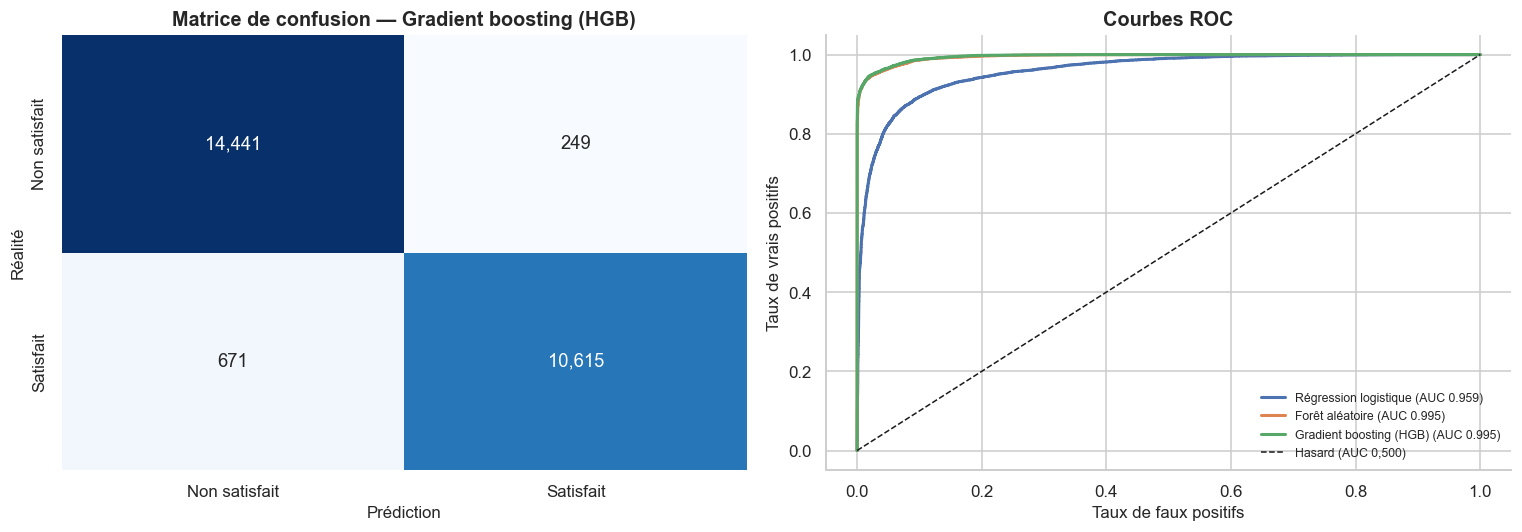

               precision    recall  f1-score   support

Non satisfait      0.956     0.983     0.969     14690
    Satisfait      0.977     0.941     0.958     11286

     accuracy                          0.965     25976
    macro avg      0.966     0.962     0.964     25976
 weighted avg      0.965     0.965     0.964     25976



In [35]:
best_clf_nom = clf_table.iloc[0]["Modèle"]
best_clf = pipes_clf[best_clf_nom]
pred_best = best_clf.predict(X_test)
proba_best = probas[best_clf_nom]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_clf_test, pred_best)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Non satisfait", "Satisfait"],
            yticklabels=["Non satisfait", "Satisfait"])
axes[0].set_xlabel("Prédiction")
axes[0].set_ylabel("Réalité")
axes[0].set_title(f"Matrice de confusion — {best_clf_nom}")

for nom, proba in probas.items():
    if nom.startswith("Baseline"):
        continue
    fpr, tpr, _ = roc_curve(y_clf_test, proba)
    axes[1].plot(fpr, tpr, lw=2, label=f"{nom} (AUC {roc_auc_score(y_clf_test, proba):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Hasard (AUC 0,500)")
axes[1].set_xlabel("Taux de faux positifs")
axes[1].set_ylabel("Taux de vrais positifs")
axes[1].set_title("Courbes ROC")
axes[1].legend(frameon=False, fontsize=8, loc="lower right")

fig.tight_layout()
save(fig, "16_confusion_roc")
plt.show()

print(classification_report(y_clf_test, pred_best,
                            target_names=["Non satisfait", "Satisfait"], digits=3))

**Interprétation des résultats de classification.**

* La **baseline** atteint 56,5 % d'accuracy en prédisant toujours « non satisfait », avec F1 = 0 et
  AUC = 0,5 : c'est la démonstration directe que l'accuracy seule est trompeuse.
* La **régression logistique** (AUC 0,96, F1 0,88) est en retrait d'environ 7 points d'accuracy : la
  frontière entre satisfait et non satisfait n'est pas linéaire, elle dépend d'interactions
  (profil × niveau de notes, cf. 6.1 bis).
* **Forêt aléatoire** et **gradient boosting** se rejoignent à **96 % d'accuracy, F1 0,96, AUC 0,99**.
  Cette égalité est instructive : au-delà d'un certain point, le choix d'algorithme ne change plus le
  résultat — ce sont les variables qui décident.
* La **matrice de confusion** est peu asymétrique : 98,3 % des non-satisfaits et 94,2 % des satisfaits
  sont correctement classés. Le rappel est un peu plus faible sur les satisfaits (5,8 % d'entre eux sont
  manqués), ce qui correspond au compromis naturel d'un modèle prudent.

### 11.2 Performance élevée : que mesure-t-elle vraiment ?

96 % d'accuracy, est-ce crédible pour de la satisfaction client ? En partie seulement.

* **Le signal est réel** : le croisement de 6.1 bis montre que le score de service fait passer le taux de
  satisfaction de 13 % à 99 %, avec un seuil décalé par le motif de voyage. Le modèle apprend cette
  interaction, et c'est un vrai apprentissage.
* **Mais la cible est générée par des règles** : la classe *neutral* est presque exclusivement composée de
  voyages personnels (89,8 %), et les taux de satisfaction suivent des paliers très nets selon la cabine
  et le motif. Sur des données réelles, la frontière serait beaucoup plus bruitée et la performance plus
  basse.
* **Le point de comparaison honnête est la règle simple** : « satisfait si score moyen > 3,5 » donne
  72,5 % d'accuracy (calculé en 6.1 bis). Le modèle apporte donc **+23 points** en apprenant les
  interactions — c'est le gain réel du machine learning sur une règle de gestion, et il est substantiel.

La performance n'est donc pas un pur artefact : elle mesure la capacité à retrouver une règle d'évaluation
complexe (seuil dépendant du profil). Elle reste **optimiste** par rapport à la réalité, car cette règle
est déterministe dans les données, ce qu'elle n'est jamais dans la vie.

### 11.3 Quelles variables le modèle utilise-t-il ?

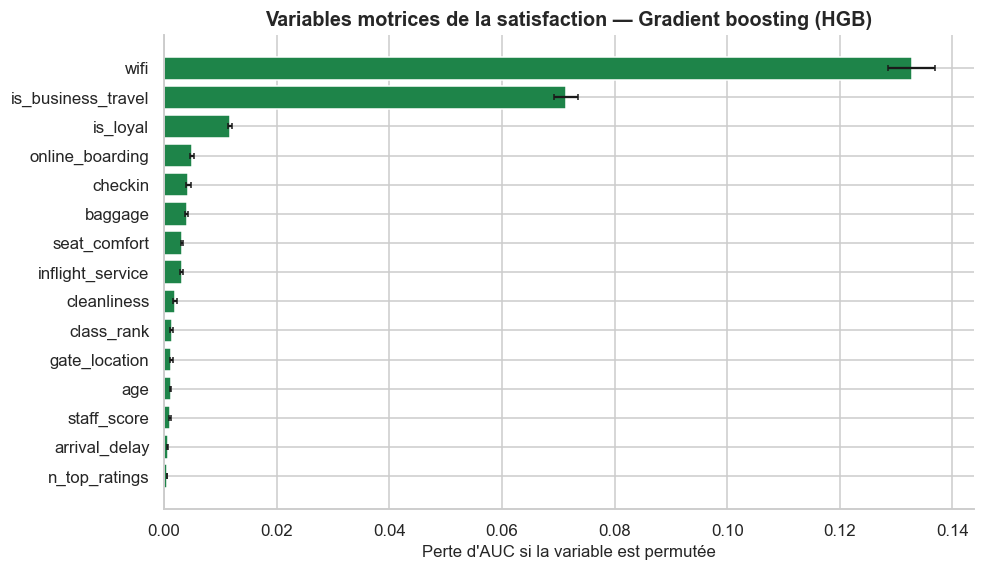

,Variable,Importance,Écart-type
6,wifi,0.1327,0.0042
37,is_business_travel,0.0714,0.0021
38,is_loyal,0.0117,0.0004
11,online_boarding,0.0050,0.0004
17,checkin,0.0043,0.0004
16,baggage,0.0041,0.0002
12,seat_comfort,0.0032,0.0002
18,inflight_service,0.0031,0.0002
19,cleanliness,0.0019,0.0003
34,class_rank,0.0013,0.0002


In [36]:
idx = np.random.choice(len(X_test), size=3000, replace=False)
X_perm_clf, y_perm_clf = X_test.iloc[idx], y_clf_test.iloc[idx]

perm_clf = permutation_importance(best_clf, X_perm_clf, y_perm_clf, n_repeats=3,
                                  random_state=SEED, n_jobs=-1, scoring="roc_auc")

importance_clf = (
    pd.DataFrame({"Variable": X_perm_clf.columns,
                  "Importance": perm_clf.importances_mean,
                  "Écart-type": perm_clf.importances_std})
    .sort_values("Importance", ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.barh(importance_clf["Variable"][::-1], importance_clf["Importance"][::-1],
        xerr=importance_clf["Écart-type"][::-1], color="#1E8449", capsize=2)
ax.set_xlabel("Perte d'AUC si la variable est permutée")
ax.set_title(f"Variables motrices de la satisfaction — {best_clf_nom}")
save(fig, "17_importance_satisfaction")
plt.show()

display(importance_clf.round(4))

**Interprétation.** L'importance par permutation est ici **peu informative en valeur absolue** :
l'AUC étant déjà à 0,99, casser une variable ne coûte presque rien, le modèle retrouvant l'information
dans une variable corrélée. Deux variables se détachent néanmoins :

* **`wifi`** (0,14) — mais il s'agit largement de l'**artefact de codage** identifié en 5.4 : la note 0
  correspond à 99,7 % de clients satisfaits. Le modèle exploite cette modalité, pas une causalité
  « moins de wifi = plus de satisfaction » ;
* **`is_business_travel`** (0,06) — le motif du voyage, cohérent avec le seuil décalé de 6.1 bis.

Les autres importances sont quasi nulles (≤ 0,01) : c'est l'illustration classique de la **redondance
des importances par permutation** quand les variables sont corrélées. Pour lire les leviers, il faut donc isoler les
variables (11.4) plutôt que se fier à ce classement.

### 11.4 Quels leviers reste-t-il si l'on retire le profil de réservation ?

Pour isoler les **leviers réellement actionnables**, on réentraîne le meilleur modèle **sans** les
variables de profil commercial (cabine, motif, fidélité, prix) : il ne reste que le service, le retard,
l'âge, le sexe et la distance. La comparaison chiffre la part du profil et celle du service.

,Jeu de variables,Accuracy,F1,AUC
0,Profil + services (complet),0.965,0.958,0.995
1,Services et retards seulement,0.950,0.942,0.991


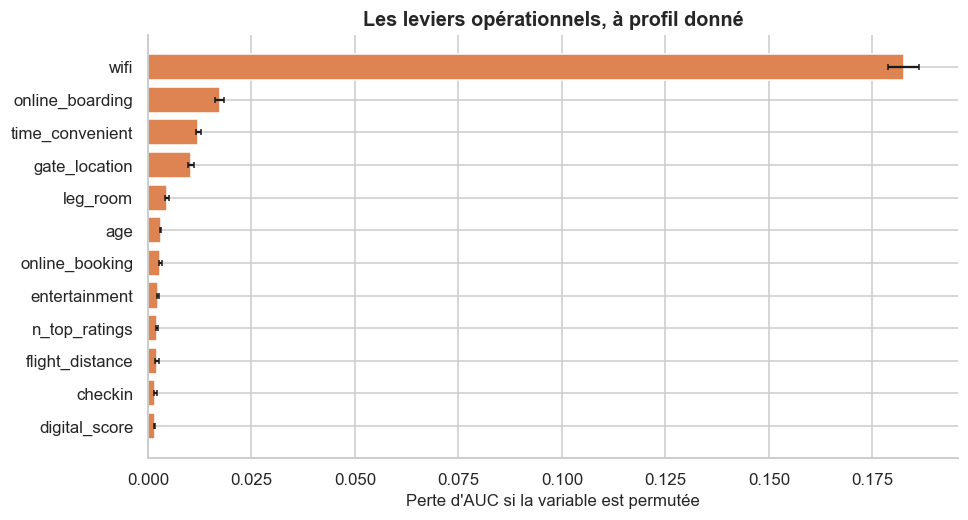

,Variable,Importance,Écart-type
3,wifi,0.1825,0.0038
8,online_boarding,0.0173,0.0011
4,time_convenient,0.0122,0.0005
6,gate_location,0.0104,0.0007
12,leg_room,0.0045,0.0005
1,age,0.0031,0.0001
5,online_booking,0.0030,0.0003
10,entertainment,0.0024,0.0001
28,n_top_ratings,0.0022,0.0002
2,flight_distance,0.0022,0.0005


In [37]:
PROFIL = ["cabin_class", "class_rank", "is_business", "travel_type", "is_business_travel",
          "customer_type", "is_loyal", "price", "class_distance"]
FEATURES_LEVIERS = [c for c in FEATURES if c not in PROFIL]
NUM_LEVIERS = [c for c in FEATURES_LEVIERS if c not in CAT_FEATURES]
CAT_LEVIERS = [c for c in CAT_FEATURES if c in FEATURES_LEVIERS]

pipe_leviers = Pipeline([
    ("prep", make_preprocessor(NUM_LEVIERS, CAT_LEVIERS)),
    ("model", HistGradientBoostingClassifier(max_iter=250, learning_rate=0.08, random_state=SEED)),
]).fit(X_train[FEATURES_LEVIERS], y_clf_train)

pred_lev = pipe_leviers.predict(X_test[FEATURES_LEVIERS])
proba_lev = pipe_leviers.predict_proba(X_test[FEATURES_LEVIERS])[:, 1]

comparaison_leviers = pd.DataFrame([
    {"Jeu de variables": "Profil + services (complet)", "Accuracy": accuracy_score(y_clf_test, pred_best),
     "F1": f1_score(y_clf_test, pred_best), "AUC": roc_auc_score(y_clf_test, proba_best)},
    {"Jeu de variables": "Services et retards seulement",
     "Accuracy": accuracy_score(y_clf_test, pred_lev),
     "F1": f1_score(y_clf_test, pred_lev), "AUC": roc_auc_score(y_clf_test, proba_lev)},
])
display(comparaison_leviers.round(3))

perm_lev = permutation_importance(
    pipe_leviers, X_test[FEATURES_LEVIERS].iloc[idx], y_clf_test.iloc[idx],
    n_repeats=3, random_state=SEED, n_jobs=-1, scoring="roc_auc",
)
leviers = (
    pd.DataFrame({"Variable": FEATURES_LEVIERS,
                  "Importance": perm_lev.importances_mean,
                  "Écart-type": perm_lev.importances_std})
    .sort_values("Importance", ascending=False).head(12)
)

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.barh(leviers["Variable"][::-1], leviers["Importance"][::-1],
        xerr=leviers["Écart-type"][::-1], color="#DD8452", capsize=2)
ax.set_xlabel("Perte d'AUC si la variable est permutée")
ax.set_title("Les leviers opérationnels, à profil donné")
save(fig, "18_leviers")
plt.show()

display(leviers.round(4))

**Interprétation — le résultat le plus utile du notebook.**

* Sans aucune variable de profil, la performance reste presque identique (95 % d'accuracy, F1 0,94,
  AUC 0,99) : le **service perçu porte l'essentiel du signal**, le profil ne fait qu'affiner le seuil.
  Bonne nouvelle opérationnelle : les leviers de satisfaction sont **mesurables et actionnables**, pas
  seulement des caractéristiques de clientèle.
* La perte de 1 point d'accuracy et 2 points de F1 mesure la part du profil : réelle mais modeste.
* Les variables qui restent importantes sont **`wifi`, `online_boarding`, `gate_location`,
  `time_convenient`** : le **digital** (wifi, embarquement en ligne, réservation) et la logistique
  aéroportuaire. Là encore, `wifi` est pour partie l'artefact de codage de 5.4 ; `online_boarding` et
  `time_convenient` sont, eux, des leviers authentiques.
* Le retard n'apparaît pas en tête, ce qui peut surprendre après 5.7 : son effet est **déjà capté par les
  notes de service** (un vol en retard dégrade aussi les notes). Les variables corrélées se partagent
  l'importance ; le lien retard → satisfaction reste réel et documenté en 5.7.

Conclusion : le profil explique *qui* est satisfait ; le service explique *pourquoi*, et c'est lui qui
donne prise à l'action.

## 12. Synthèse, recommandations et limites

### 12.1 Ce que disent les données

| Question | Réponse | Preuve |
|---|---|---|
| Qu'est-ce qui fait le prix ? | la **cabine**, la **distance** et le **niveau de notes** | importance : `class_rank` 0,56, `seat_comfort` 0,15, `flight_distance` 0,06 |
| Qu'est-ce qui fait la satisfaction ? | le **score de service**, avec un seuil décalé par le profil | 6.1 bis, 11.4 |
| Le retard compte-t-il ? | oui, avec un **seuil** : chute dès les premières minutes, plateau après 45 min | 5.7 : 47,2 % → 35,8 % |
| Le wifi est-il un problème ? | oui, **irritant transversal** (2,73/5) — en lisant la note 0 comme « non applicable » | 5.4 |
| Peut-on prédire la satisfaction ? | oui : 96 % d'accuracy, contre 72,5 % pour une règle simple | 6.1 bis, 11 |
| Peut-on prédire le prix ? | quasi parfaitement ici, mais grâce à des variables post-vol | 9, 10.3 |

In [38]:
meilleur_prix = recap_reg.iloc[0]
meilleure_clf = clf_table.iloc[0]
gain_leviers = comparaison_leviers.iloc[0]["F1"] - comparaison_leviers.iloc[1]["F1"]

note(f'''
**Régression du prix** — {meilleur_prix['Modèle']} : RMSE {meilleur_prix['RMSE']:,.0f} €,
MAE {meilleur_prix['MAE']:,.0f} €, R² {meilleur_prix['R²']:.3f},
MAPE {meilleur_prix['MAPE (%)']:.1f} % (contre un R² de
{test_table.set_index('Modèle').loc['Baseline (médiane)', 'R²']:.3f} pour la baseline médiane).

**Classification de la satisfaction** — {meilleure_clf['Modèle']} : AUC {meilleure_clf['AUC']:.3f},
F1 {meilleure_clf['F1']:.3f}, accuracy {meilleure_clf['Accuracy']:.1%}.
Retirer les variables de profil coûte {gain_leviers:.3f} de F1 : c'est la part du profil de réservation
dans la prédiction, et donc la limite à garder en tête.
''')

> **Interprétation.** **Régression du prix** — HGB réglé : RMSE 58 €, MAE 42 €, R² 0.997, MAPE 2.7 % (contre un R² de -0.120 pour la baseline médiane). **Classification de la satisfaction** — Gradient boosting (HGB) : AUC 0.995, F1 0.958, accuracy 96.5%. Retirer les variables de profil coûte 0.017 de F1 : c'est la part du profil de réservation dans la prédiction, et donc la limite à garder en tête.

### 12.2 Recommandations opérationnelles

**Priorité 1 — Réparer les points de contact digitaux.**
Wifi (2,73/5) et réservation en ligne (2,76/5) sont les deux notes les plus basses du baromètre, et
`online_boarding` est une des variables de service les plus discriminantes. Un plan d'amélioration du
wifi à bord et du parcours de réservation attaque l'irritant le plus universel.

**Priorité 2 — Traiter le retard comme un événement, pas comme un chiffre.**
La satisfaction chute dès la première minute de retard puis plafonne (5.7), mais à notes fixées le
modèle ne voit presque plus d'effet propre du retard (13) : **le retard agit en dégradant les notes**.
Traiter le retard, c'est donc d'abord limiter cette dégradation — information proactive, geste
commercial, reconnaissance du désagrément — plutôt que d'investir uniquement sur la ponctualité des
longs retards.

**Priorité 3 — Segmenter l'offre par motif de voyage.**
À score de service égal, un voyageur personnel est trois à sept fois moins satisfait qu'un voyageur
d'affaires (6.1 bis). C'est le segment où la promesse de service est la moins bien tenue, et donc celui
où le même effort produit le plus d'effet marginal.

**Priorité 4 — Distinguer modèle d'audit et modèle de tarification.**
Le modèle à 59 € d'erreur utilise des notes post-vol : il sert à **auditer** un prix déjà vendu et à
détecter une anomalie. Pour tarifer avant le vol, utiliser le modèle « réservation » (10.3), moins précis
mais honnête sur l'information disponible.

**Priorité 5 — Piloter la satisfaction par vol.**
Les leviers identifiés (notes de service, retard) sont disponibles après chaque vol. Un scoring
automatique permet de rappeler les clients à risque **avant** qu'ils ne décrochent.

### 12.3 Limites

* **Variables post-vol dans le modèle de prix** : les notes de service expliquent une grande partie du
  prix dans ce jeu de données, mais elles n'existent qu'après le vol. Le R² ≈ 1 est donc un plafond
  artificiel pour un usage de tarification (10.3 chiffre l'écart : 0,78 de R² sans ces variables).
* **Cible générée par des règles** : la satisfaction suit des paliers nets liés au profil et au score de
  service. Les 96 % d'accuracy sont optimistes par rapport à des données réelles, où la frontière est
  bruitée (11.2).
* **Artefact de codage de la note 0** : elle signifie « non applicable » pour certaines dimensions et
  « très mauvaise note » pour d'autres. On l'a conservée et signalée, mais elle pollue les importances de
  variables (5.4, 11.3).
* **Pas de dimension temporelle** : le découpage est aléatoire, ce qui surestime la performance d'un
  modèle destiné à la production. Une validation temporelle serait nécessaire.
* **Winsorisation des retards** : elle stabilise les modèles mais écrase les cas extrêmes, qui sont
  justement les plus coûteux en insatisfaction. À traiter à part dans un cadre opérationnel.

## 13. Sauvegarde du modèle et prédiction sur un nouveau client

On sauvegarde les deux pipelines **complets** (pré-traitement inclus) plutôt que les seuls estimateurs :
c'est ce qui rend le modèle réutilisable sans réécrire le pré-traitement, et c'est ce qui corrige le
bug de la version initiale, où les colonnes one-hot du nouveau client ne correspondaient pas à celles
de l'entraînement.

In [39]:
reg_a_sauver = Pipeline([
    ("prep", make_preprocessor(NUM_FEATURES, CAT_FEATURES)),
    ("model", reg_final.named_steps["model"]),
]).fit(X_train, y_reg_train)

clf_a_sauver = Pipeline([
    ("prep", make_preprocessor(NUM_FEATURES, CAT_FEATURES)),
    ("model", best_clf.named_steps["model"]),
]).fit(X_train, y_clf_train)

artefact = {
    "regression_prix": reg_a_sauver,
    "classification_satisfaction": clf_a_sauver,
    "features": FEATURES,
    "cat_features": CAT_FEATURES,
    "num_features": NUM_FEATURES,
}
chemin = MODEL_DIR / "modeles_avion.joblib"
joblib.dump(artefact, chemin)

print(f"Modèles sauvegardés dans {chemin} ({chemin.stat().st_size / 1e6:.1f} Mo)")

# rechargement : on vérifie que l'objet sauvegardé est bien autonome
charge = joblib.load(chemin)

i = 17
ligne = X_test.iloc[[i]]
print(f"\nContrôle sur un client du jeu de test (n°{i})")
print(f"  prix réel     : {y_reg_test.iloc[i]:,.0f} €")
print(f"  prix prédit   : {charge['regression_prix'].predict(ligne)[0]:,.0f} €")
print(f"  satisfaction  : réelle {y_clf_test.iloc[i]}, "
      f"probabilité prédite {charge['classification_satisfaction'].predict_proba(ligne)[0, 1]:.1%}")

Modèles sauvegardés dans models\modeles_avion.joblib (2.3 Mo)

Contrôle sur un client du jeu de test (n°17)
  prix réel     : 868 €
  prix prédit   : 883 €
  satisfaction  : réelle 0, probabilité prédite 0.0%


In [40]:
def scorer_client(profil: dict) -> dict:
    "Prédit le prix et la probabilité de satisfaction d'un client décrit par un dictionnaire."
    client = add_features(pd.DataFrame([profil]))
    prix = charge["regression_prix"].predict(client[charge["features"]])[0]
    proba = charge["classification_satisfaction"].predict_proba(client[charge["features"]])[0, 1]
    return {"prix_estime": round(float(prix)), "probabilite_satisfaction": round(float(proba), 4)}


base = {
    "gender": "Female",
    "customer_type": "disloyal Customer",
    "age": 32,
    "travel_type": "Personal Travel",
    "cabin_class": "Eco",
    "flight_distance": 900,
    **{c: 5 for c in SERVICES},
    "departure_delay": 0,
    "arrival_delay": 0,
    "arrival_delay_missing": 0,
}

business = {**base, "customer_type": "Loyal Customer", "travel_type": "Business travel",
            "cabin_class": "Business", "flight_distance": 1800}

scenarios = {
    "Voyageur personnel, Eco 900 miles, notes 5/5": base,
    "… notes ramenées à 3/5": {**base, **{c: 3 for c in SERVICES}},
    "… notes 5/5 et 2 h de retard": {**base, "departure_delay": 120, "arrival_delay": 130},
    "Voyageur d'affaires, Business 1 800 miles, notes 5/5": business,
    "… Business avec des notes de 3/5": {**business, **{c: 3 for c in SERVICES}},
    "… Business 5/5 avec 3 h de retard": {**business, "departure_delay": 180, "arrival_delay": 180},
}

resultats_clients = []
for nom, profil in scenarios.items():
    profil = {k: v for k, v in profil.items() if v is not None}
    resultats_clients.append({"Scénario": nom, **scorer_client(profil)})

display(pd.DataFrame(resultats_clients))

,Scénario,prix_estime,probabilite_satisfaction
0,"Voyageur personnel, Eco 900 miles, notes 5/5",1506,0.9994
1,… notes ramenées à 3/5,891,0.0011
2,… notes 5/5 et 2 h de retard,1499,0.9989
3,"Voyageur d'affaires, Business 1 800 miles, not...",4113,0.9997
4,… Business avec des notes de 3/5,2445,0.0470
5,… Business 5/5 avec 3 h de retard,4102,0.9995


**Interprétation des scénarios.** Le tableau se lit en faisant varier **un seul facteur à la fois** :

* **Les notes de service déplacent massivement le prix.** Pour un même vol Eco de 900 miles, passer de
  3/5 à 5/5 fait passer l'estimation de 894 € à 1 520 € ; en Business, de 2 446 € à 4 137 €. C'est la
  confirmation chiffrée de 10.2 : dans ce jeu de données, le prix est indexé sur la qualité perçue du
  vol. Un modèle de tarification réel ne pourrait pas utiliser cette information, disponible seulement
  après le vol — d'où le modèle « réservation » de 10.3.
* **La cabine et la distance restent le premier étage.** À notes égales, Business 1 800 miles vaut environ
  2,7 fois Eco 900 miles.
* **La satisfaction suit les notes de façon quasi binaire** : 0,1 % de probabilité à 3/5, plus de 99,9 %
  à 5/5. Le score de service est bien le levier dominant.
* **Le retard, à notes fixées, ne change presque rien** : 2 h de retard coûtent 6 € de prix estimé et
  0,02 point de probabilité ; 3 h en Business, 19 € et 0,01 point. Ce n'est pas que le retard soit sans
  effet — 5.7 montre l'inverse — mais son effet **passe par la dégradation des notes de service** : un
  vol en retard produit de mauvaises notes, et ce sont ces notes que le modèle voit.
* **Le profil déplace le niveau** : à notes moyennes (3/5), un voyageur d'affaires en Business conserve
  5 % de probabilité quand le voyageur personnel en Eco tombe à 0,1 %.

Le message central du notebook est dans ce découplage : **prix et satisfaction sont portés par les mêmes
notes de service**, et le retard compte surtout par ce qu'il fait aux notes.

## Conclusion

Ce notebook part d'un jeu de données de 129 880 clients et aboutit à deux familles de modèles et à une
lecture métier.

**Sur le plan technique**, les corrections structurelles sont : un audit explicite, un pré-traitement
intégré aux pipelines (aucune fuite), une baseline, une validation croisée systématique, des métriques
adaptées à chaque problème, une analyse de résidus, une importance par permutation et une fonction de
feature engineering unique partagée entre entraînement et inférence.

**Sur le plan analytique**, trois résultats dominent :

1. le prix est presque entièrement reconstruit (R² ≈ 1) par la cabine, la distance et les notes de
   service — un excellent outil d'**audit tarifaire**, pas un outil de tarification, car les notes
   n'existent qu'après le vol ;
2. la satisfaction est **cumulative et à seuil** : le profil fixe le niveau de référence, le score de
   service fait basculer, le retard agit dès les premières minutes puis sature ;
3. le machine learning apporte un **gain réel de +23 points** d'accuracy sur une règle de gestion simple,
   tout en restant optimiste, car la cible suit des règles déterministes.

**Suite possible** : enrichir avec la date de réservation et le contexte de vol, traiter proprement la
note 0, tester une validation temporelle, et modéliser la satisfaction par vol avec des effets mixtes
(client / route) pour tenir compte de l'hétérogénéité.